# Field 643: the filtering pipeline, end to end

`Extracting.field_tables.build_field` makes the field tables (per-band ZTF catalogs with our Kron photometry, deduplicated across quadrant overlaps; the band-merged objects; the deduplicated PS1 catalog on valid ZTF pixels; the 1" match). `Source_Analysis.filter_field.filter_field` then assigns every object's bands to `in_both` / `in_ztf` / `in_pstarr` with the SNR hand-off and upper limits, decides morphology from both catalogs, builds one envelope per band on the `in_both` quality sample, and runs the three branches. This notebook runs both on the quadrants available locally and shows the flowcharts, the envelopes and the candidates.

Sections 2–4 are the development record: they run the per-band morphology rule with every Kron aperture kept (`filter_dev(base, 'combined', 'none')`) and compare the alternatives through the development copy of the catalog assignment defined below. `ff` itself runs only the final pipeline, shown in section 5: one catalog and one morphology (vote) per object, bands with a contaminated ZTF Kron aperture dropped, and every cut removing a band for good.

In [1]:
import os, sys
sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import norm
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord
from astropy.visualization import simple_norm
import astropy.units as u
from Extracting import field_tables as ft
from Extracting.images import load_ztf_refimg
from Extracting.ztf_images import refimg_path
from Source_Analysis import filter_field as ff

FIELD = 643
D = '../Data'
QUADRANTS = sorted({(int(f.split('_c')[1][:2]), int(f.split('_q')[1][0])) for f in os.listdir(f'{D}/ztf_data') if f.startswith(f'ztf_{FIELD:06d}') and f.endswith('_refsexcat.fits')})
QUADRANTS = [q for q in QUADRANTS if all(os.path.exists(refimg_path(f'{D}/ztf_data', FIELD, *q, b, p)) for b in 'gri' for p in ('refimg', 'refunc', 'refcov', 'refpsfcat', 'refsexcat'))]
print('quadrants with every product:', QUADRANTS)

CasJobs will use the credentials from mast_dino_login.txt
The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.
quadrants with every product: [(1, 1), (1, 2), (1, 3), (1, 4), (2, 1), (2, 2), (2, 3), (2, 4), (3, 1), (3, 2), (3, 3), (3, 4), (4, 1), (4, 2), (4, 3), (4, 4), (5, 1), (5, 2), (5, 3), (5, 4), (6, 1), (6, 2), (6, 3), (6, 4), (7, 1), (7, 2), (7, 3), (7, 4), (8, 1), (8, 2), (8, 3), (8, 4), (9, 1), (9, 2), (9, 3), (9, 4), (10, 1), (10, 2), (10, 3), (10, 4), (11, 1), (11, 2), (11, 3), (11, 4), (12, 1), (12, 2), (12, 3), (12, 4), (13, 1), (13, 2), (13, 3), (13, 4), (14, 1), (14, 2), (14, 3), (14, 4), (15, 1), (15, 2), (15, 3), (15, 4), (16, 1), (16, 2), (16, 3), (16, 4)]


### Development variants

`assign_catalogs_dev` is `ff.assign_catalogs` with the morphology rules (`combined`, `agree`, `vote`, `multiband`) and contaminated-Kron treatments (`none`, `drop`, `psf`) compared below; `filter_dev` runs it through the rest of `ff`. These run the per-band pipeline the sections below were developed with (each band assigned to a catalog on its own, the ≥ 2 bands cut re-merging them); `ff` now decides everything per object (section 5).

In [2]:
# Development variants: the morphology rules and contaminated-Kron treatments compared in sections 2-3. ff itself runs only
# the final choice (morphology='vote', kron_policy='drop'), decided per object rather than per band.
from source_db.constants import PSTARR_UPPER_LIM

def side_extendedness(src, b, side):
    """One catalog's (PSF - Kron - cut) / sqrt(err_PSF^2 + err_Kron^2); NaN where it has no PSF or Kron magnitude."""
    excess = src[f'{b}_{side}_psf'].values - src[f'{b}_{side}_kron'].values - ff.PSF_KRON_CUT
    return excess / np.hypot(src[f'{b}_{side}_psf_err'].values, src[f'{b}_{side}_kron_err'].values)

def assign_catalogs_dev(src, kron_policy='drop', morphology='vote'):
    """ff.assign_catalogs with the alternatives. morphology: 'combined' (per band, both catalogs' PSF - Kron significance
    combined by inverse variance > PSF_KRON_NSIGMA), 'agree' (per band, each catalog that measured it passes; both for
    in_both), 'vote' (per object, the per-band statistic passes in >= 2 measured bands) or 'multiband' (per object, the
    combination over all bands and both catalogs passes). kron_policy for extended sources with a contaminated ZTF Kron
    aperture: 'none' uses Kron anyway, 'drop' removes the band, 'psf' uses PSF magnitudes."""
    cols, obj_point = {}, None
    if morphology == 'vote':
        obj_point = ff.point_source(src)
    elif morphology == 'multiband':
        num = np.zeros(len(src)); den = np.zeros(len(src))
        for b in 'gri':
            for side in ('ps1', 'ztf'):
                excess = src[f'{b}_{side}_psf'].values - src[f'{b}_{side}_kron'].values - ff.PSF_KRON_CUT
                var = src[f'{b}_{side}_psf_err'].values ** 2 + src[f'{b}_{side}_kron_err'].values ** 2
                ok = np.isfinite(excess) & (var > 0)
                num[ok] += excess[ok] / var[ok]; den[ok] += 1.0 / var[ok]
        obj_point = ~(np.where(den > 0, num / np.sqrt(np.where(den > 0, den, 1.0)), -np.inf) > ff.PSF_KRON_NSIGMA)
    for b in 'gri':
        det_z, det_p = src[f'{b}_ztf_det'].values, src[f'{b}_ps1_meas'].values
        q_z, q_p = src[f'{b}_ztf_quality'].values, det_p & src['ps1_quality'].values
        snr_z = q_z & (src[f'{b}_ztf_snr'].values >= ff.SNR_MIN)
        snr_p = q_p & (src[f'{b}_ps1_snr'].values >= ff.SNR_MIN)
        both = det_z & det_p
        both_q = both & q_z & q_p
        ztf_init = (det_z & ~det_p) | (both_q & ~snr_p)
        ps1_init = ((det_p & ~det_z) | (both_q & ~snr_z)) & src[f'{b}_ztf_covered'].values
        cat = np.full(len(src), -1, np.int8)
        cat[ztf_init & snr_z] = 1
        cat[ps1_init & snr_p] = 2
        cat[both_q & snr_z & snr_p] = 0
        S = ff.extendedness(src, b)
        if morphology == 'combined':
            point = ~(S > ff.PSF_KRON_NSIGMA)
        elif obj_point is not None:
            point = obj_point.copy()
        else:
            sz, sp = side_extendedness(src, b, 'ztf'), side_extendedness(src, b, 'ps1')
            mz, mp = np.isfinite(sz), np.isfinite(sp)
            ext = (~mz | (sz > ff.PSF_KRON_NSIGMA)) & (~mp | (sp > ff.PSF_KRON_NSIGMA)) & (mz | mp)
            ext &= (cat != 0) | (mz & mp)
            point = ~ext
        contaminated = (cat >= 0) & (cat != 2) & ~point & ~(src[f'{b}_ztf_kron_masked'].values <= ff.KRON_MAX_MASKED)
        if kron_policy == 'drop':
            cat[contaminated] = -1
        use_kron = (cat >= 0) & ~point & ~(contaminated & (kron_policy == 'psf'))
        use_kron &= ((cat == 2) | np.isfinite(src[f'{b}_ztf_kron'].values)) & ((cat == 1) | np.isfinite(src[f'{b}_ps1_kron'].values))
        z_mag = np.where(use_kron, src[f'{b}_ztf_kron'].values, src[f'{b}_ztf_psf'].values)
        z_err = np.where(use_kron, src[f'{b}_ztf_kron_err'].values, src[f'{b}_ztf_psf_err'].values)
        p_mag = np.where(use_kron, src[f'{b}_ps1_kron'].values, src[f'{b}_ps1_psf'].values)
        p_err = np.where(use_kron, src[f'{b}_ps1_kron_err'].values, src[f'{b}_ps1_psf_err'].values)
        cols.update({
            f'{b}_both_det': both, f'{b}_both_quality': both_q, f'{b}_ztf_initial': ztf_init, f'{b}_pstarr_initial': ps1_init,
            f'{b}_cat': cat, f'{b}_extendedness': S, f'{b}_point': point,
            f'{b}_kron_contaminated': contaminated, f'{b}_use_kron': use_kron,
            f'{b}_ztf_use': np.where(cat == 2, src[f'{b}_ztf_maglim'].values, z_mag), f'{b}_ztf_use_err': np.where(cat == 2, 0.0, z_err),
            f'{b}_ps1_use': np.where(cat == 1, PSTARR_UPPER_LIM[b], p_mag), f'{b}_ps1_use_err': np.where(cat == 1, 0.0, p_err),
        })
    return ff._attach(src, cols)

# The per-band branches the sections below were developed with (ff now decides everything per object): each band of an
# object is assigned to in_both / in_ztf / in_pstarr on its own, and the >= 2 bands cut re-merges them per catalog.
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple
from Source_Analysis.filter_field import (BANDS, CATALOG, COMBOS, KRON_MAX_MASKED, NAN_RADIUS_PX, PS1_CUTS,
                                          SIGMA_BOUNDARY, SNR_MIN)

COUNTERPART_ARCSEC = 3.0        # one-sided rows with an unmatched source on the other side within this are dropped

def _unmatched_counterpart(src, catalog, rows=None):
    """Rows (all, or those in the boolean `rows`) with a source on the other side within COUNTERPART_ARCSEC that is not
    their 1\" match."""
    from scipy.spatial import cKDTree
    cosd = np.cos(np.radians(src.dec.median()))
    xy = np.c_[src.ra.values * cosd, src.dec.values]
    is_ztf = src.ztf_idx.values >= 0
    pool = (~is_ztf) | (src.ps1_idx.values >= 0) if catalog == 1 else is_ztf
    tree = cKDTree(xy[pool]); pool_idx = np.flatnonzero(pool)
    which = np.flatnonzero(rows) if rows is not None else np.arange(len(src))
    flag = np.zeros(len(src), bool)
    for i, hits in zip(which, tree.query_ball_point(xy[which], r=COUNTERPART_ARCSEC / 3600.0)):
        flag[i] = any(pool_idx[h] != i for h in hits)
    return flag

@dataclass
class WaterfallDev:
    """One branch's record: the cumulative keep-mask after each step, per band. Steps from the >= 2 bands cut on are
    object-level (`objects`): they are counted as merged objects split by the exact combination of big-dmag bands, as in
    the old pipeline's flowcharts."""
    catalog: str
    steps: List[str] = field(default_factory=list)
    packed: List[Dict[str, np.ndarray]] = field(default_factory=list)     # step -> {band: rows still in, bit-packed}
    counts: List[Dict[str, int]] = field(default_factory=list)
    objects: List[bool] = field(default_factory=list)
    n_rows: int = 0

    def add(self, label: str, band_masks: Dict[str, np.ndarray], objects: bool = False):
        self.n_rows = len(next(iter(band_masks.values())))
        self.steps.append(label)
        self.objects.append(objects)
        self.packed.append({b: np.packbits(np.asarray(m, bool)) for b, m in band_masks.items()})
        if objects:
            m = {b: np.asarray(band_masks[b], bool) for b in BANDS}
            exact = lambda combo: np.logical_and.reduce([m[b] if b in combo else ~m[b] for b in BANDS])
            c = {k: int(np.count_nonzero(exact(k))) for k in COMBOS}
            self.counts.append({'objects': sum(c.values()), **c})
        else:
            self.counts.append({b: int(np.count_nonzero(m)) for b, m in band_masks.items()})

    def mask(self, i: int) -> Dict[str, np.ndarray]:
        """The per-band keep-masks after step i (an index into `steps`)."""
        return {b: np.unpackbits(p, count=self.n_rows).astype(bool) for b, p in self.packed[i].items()}

    @property
    def masks(self) -> List[Dict[str, np.ndarray]]:
        return [self.mask(i) for i in range(len(self.steps))]

    @property
    def stats(self) -> pd.DataFrame:
        """Rows left after each step: g, r, i for the per-band steps; objects and their band combinations after."""
        cols = list(BANDS) + ['objects', *COMBOS]
        return pd.DataFrame([{'step': s, **c} for s, c in zip(self.steps, self.counts)], columns=['step'] + cols).astype({c: 'Int64' for c in cols})

    def dropped_by(self, label: str) -> Dict[str, np.ndarray]:
        i = self.steps.index(label)
        before, after = self.mask(i - 1), self.mask(i)
        return {b: before[b] & ~after[b] for b in BANDS}

    def flowchart(self, title: Optional[str] = None):
        """Flowchart in the old pipeline's style: per-band counts (fraction of the start) for per-band steps, objects and
        their band combinations for object-level steps; boxes sized to their text, the cut on each arrow."""
        import schemdraw
        from schemdraw import flow
        from schemdraw.elements import Line
        from Source_Analysis.filter_fields import _box_width_for_text, format_two_sig_figs
        init = self.counts[0]
        def text(c):
            if 'objects' in c:
                return f"objects: {c['objects']:,}\n" + '\n'.join(f'{k}: {c[k]:,}' for k in COMBOS)
            return '\n'.join(f'{b}: {c[b]:,} ({format_two_sig_figs(c[b] / init[b] if init[b] else 0.0)})' for b in BANDS)
        size = lambda t, pad: (_box_width_for_text(t, padding=pad), 0.45 * (t.count('\n') + 1) + 0.4)
        label_w = max(_box_width_for_text(l, padding=0.0) for l in self.steps[1:]) if len(self.steps) > 1 else 0.0
        with schemdraw.Drawing(show=False) as d:
            t = f'{title or self.catalog}\n' + text(init)
            w, h = size(t, 1.0)
            prev = d.add(flow.Start(w=w, h=h).label(t))
            for label, c in zip(self.steps[1:], self.counts[1:]):
                d += flow.Arrow().down(d.unit / 2).at(prev.S).label(label)
                t = text(c); w, h = size(t, 0.5)
                prev = d.add(flow.Box(w=w, h=h).anchor('N').label(t))
            d += Line().at((-label_w - 4.0, 0)).to((-label_w - 3.99, 0)).color('none')   # room for the arrow labels
        return d


def run_branch_dev(src: pd.DataFrame, catalog: int) -> Tuple[pd.DataFrame, WaterfallDev]:
    """One catalog's filter chain, every cut its own waterfall step. Returns (candidates, waterfall).

    The per-band steps up to the SNR / Kron cuts reproduce `assign_catalogs` exactly (checked against `{b}_cat`): a side
    that fails SNR moves the band to the one-sided branch, which is where those rows reappear."""
    name = CATALOG[catalog]
    wf = WaterfallDev(name)
    col = lambda c: {b: src[f'{b}_{c}'].values for b in BANDS}
    det_z, det_p, both_q = col('ztf_det'), col('ps1_meas'), col('both_quality')
    snr_z = {b: src[f'{b}_ztf_snr'].values >= SNR_MIN for b in BANDS}
    snr_p = {b: src[f'{b}_ps1_snr'].values >= SNR_MIN for b in BANDS}
    ztf_cuts = [('ZTF: DAOPhot flags = 0', col('ztf_flags_ok')), (f'ZTF: > {NAN_RADIUS_PX} px from a masked pixel', col('ztf_clear'))]
    ps1_cuts = [(label, {b: src[f'ps1_q_{nm}'].values & det_p[b] for b in BANDS}) for nm, label, _ in PS1_CUTS]
    m = {}
    stages = []
    def step(label, cut):
        for b in BANDS:
            m[b] = m[b] & cut[b]
        stages.append((label, {b: m[b].copy() for b in BANDS}))
    if catalog == 0:
        m.update({b: det_z[b] & det_p[b] for b in BANDS}); stages.append(('detected in ZTF and PS1', {b: m[b].copy() for b in BANDS}))
        for label, cut in ztf_cuts + ps1_cuts:
            step(label, cut)
        step(f'ZTF: PSF SNR >= {SNR_MIN:.0f} (else -> in_pstarr)', snr_z)
        step(f'PS1: PSF SNR >= {SNR_MIN:.0f} (else -> in_ztf)', snr_p)
    elif catalog == 1:
        m.update({b: (det_z[b] & ~det_p[b]) | (both_q[b] & ~snr_p[b]) for b in BANDS})
        stages.append((f'ZTF only: PS1 undetected or PS1 SNR < {SNR_MIN:.0f}', {b: m[b].copy() for b in BANDS}))
        for label, cut in ztf_cuts:
            step(label, cut)
        step(f'ZTF: PSF SNR >= {SNR_MIN:.0f}', snr_z)
    else:
        m.update({b: (det_p[b] & ~det_z[b]) | (both_q[b] & ~snr_z[b]) for b in BANDS})
        stages.append((f'PS1 only: ZTF undetected or ZTF SNR < {SNR_MIN:.0f}', {b: m[b].copy() for b in BANDS}))
        step('ZTF image covers the position', col('ztf_covered'))
        for label, cut in ps1_cuts:
            step(label, cut)
        step(f'PS1: PSF SNR >= {SNR_MIN:.0f}', snr_p)
    if catalog != 2:
        contaminated = col('kron_contaminated')
        step(f'extended: ZTF Kron aperture <= {100*KRON_MAX_MASKED:.0f}% masked', {b: ~contaminated[b] for b in BANDS})
    for b in BANDS:
        assert np.array_equal(m[b], src[f'{b}_cat'].values == catalog), f'{name} {b}: waterfall does not reproduce assign_catalogs'
    for label, band_in in stages:
        wf.add(label, band_in)
    band_in = stages[-1][1]
    big = {b: band_in[b] & (np.abs(src[f'{b}_sigma'].values) > SIGMA_BOUNDARY) for b in BANDS}
    wf.add(f'|σ| > {SIGMA_BOUNDARY:.0f} against the envelope', big)
    keep = sum(big[b].astype(int) for b in BANDS) >= 2
    per_band = lambda k: {b: k & big[b] for b in BANDS}
    wf.add(f'|σ| > {SIGMA_BOUNDARY:.0f} in >= 2 bands', per_band(keep), objects=True)
    if catalog != 0:
        keep &= ~_unmatched_counterpart(src, catalog, rows=keep)
        wf.add(f'no unmatched counterpart within {COUNTERPART_ARCSEC:.0f}"', per_band(keep), objects=True)
    keep &= ~(src['gaia_pm_sig'].values >= 5.0)
    wf.add('Gaia: no proper motion at 5σ', per_band(keep), objects=True)
    keep &= ~(src['gaia_parallax_over_error'].values >= 5.0)
    wf.add('Gaia: no parallax at 5σ', per_band(keep), objects=True)
    cand = src[keep].copy()
    cand['catalog'] = name
    cand['n_big_dmag_bands'] = sum(big[b][keep].astype(int) for b in BANDS)
    return cand, wf


def filter_dev(base, morphology='vote', kron_policy='drop', verbose=False):
    """The per-band pipeline with assign_catalogs_dev. Returns (src, envelopes, candidates, waterfalls)."""
    src = assign_catalogs_dev(base, kron_policy=kron_policy, morphology=morphology)
    envelopes = ff.kde_envelopes(ff.envelope_tables(src))
    src = ff.annotate_sigma(src, envelopes)
    # ff.run_branch drops contaminated Kron as its own step; under 'none'/'psf' nothing is dropped, so hide that step
    br = src if kron_policy == 'drop' else src.assign(**{f'{b}_kron_contaminated': np.zeros(len(src), bool) for b in 'gri'})
    cands, wfs = {}, {}
    for c, name in ff.CATALOG.items():
        if verbose: print(f'Filtering {name}')
        cands[name], wf = run_branch_dev(br, c)
        if kron_policy != 'drop' and c != 2:
            i = next(i for i, s in enumerate(wf.steps) if s.startswith('extended: ZTF Kron'))
            for lst in (wf.steps, wf.packed, wf.counts, wf.objects): del lst[i]
        wfs[name] = wf
    return src, envelopes, cands, wfs

## 1. Field tables

In [3]:
bands, obj, ps1 = ft.build_field(FIELD, QUADRANTS, data_dir=D, n_jobs=6)
for b, cat in bands.items():
    print(f'{b}: {len(cat)} sources after dropping {cat.n_duplicates_dropped.iloc[0]} overlap duplicates; Kron for {np.isfinite(cat.zkron).mean()*100:.1f}%; floor {cat.zkron_floor_arcsec.iloc[0]:.2f}"')
print(f'objects: {len(obj)} (3/2/1 bands: {(obj.nbands==3).sum()}/{(obj.nbands==2).sum()}/{(obj.nbands==1).sum()}); PS1 inside the footprint: {len(ps1)} ({ps1.on_ztf.sum()} on valid pixels); matched: {obj.matched.sum()}')

g: 3066393 sources after dropping 0 overlap duplicates; Kron for 82.8%; floor 1.13"
r: 3981605 sources after dropping 0 overlap duplicates; Kron for 87.3%; floor 1.11"
i: 4290358 sources after dropping 0 overlap duplicates; Kron for 87.9%; floor 1.27"
objects: 6483053 (3/2/1 bands: 1838334/1178635/3466084); PS1 inside the footprint: 3976302 (3679771 on valid pixels); matched: 3148540


## 2. Filtering

In [15]:
base = ff.prepare_field(FIELD, data_dir=D)            # object table + Gaia match; reused by the variant runs below
src, envelopes, cands, wfs = filter_dev(base, morphology='combined', kron_policy='none')
print(f'{len(src)} rows: {(src.ztf_idx >= 0).sum()} ZTF objects ({src.matched.sum() if "matched" in src else (src.ps1_idx[src.ztf_idx >= 0] >= 0).sum()} matched to PS1) + {(src.ztf_idx < 0).sum()} PS1-only objects')

/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "pmsafe" yielded 1466991 of "distance overridden (Note 6)", 133 of "binary logical OR of the above warnings"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


StopIteration: 

## 2a. Validating the constructed tables

Before any cut: what the catalog assignment produced. Per band, every row is `in_both` (ZTF and PS1 both detected, both pass quality, both SNR ≥ 5), `in_ztf`, `in_pstarr` or unusable, and a one-sided band can come either from the other survey having no detection or from it failing SNR (the hand-off). Then the band multiplicities, the per-object catalog pattern across g, r, i, the magnitude distributions per catalog, the match separations, and where on the sky the one-sided rows sit.

band,g,r,i
in_both,1400297,2080326,2458568
in_ztf: PS1 undetected,391039,715120,541848
in_ztf: PS1 SNR<5 hand-off,910,1920,321
in_pstarr: ZTF undetected,100829,72897,129442
in_pstarr: ZTF SNR<5 hand-off,68590,34011,44234
"unusable: ZTF det, fails quality",37760,59305,45353
"unusable: PS1 meas, fails quality",435091,536316,865250
unusable: SNR<5 (ZTF only side),1095718,950714,824657
unusable: SNR<5 (PS1 only side),656,331,122
unusable: both sides SNR<5,505,343,62


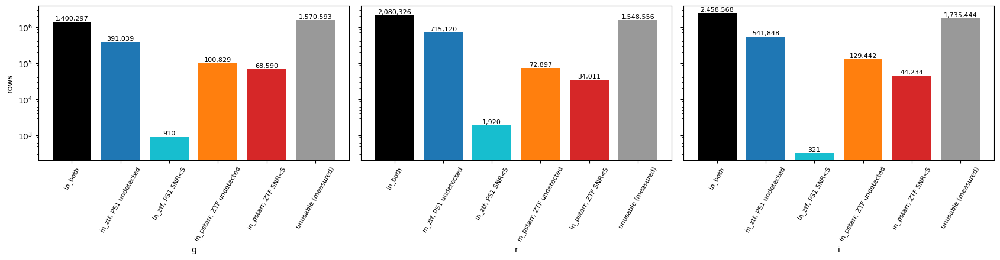

In [ ]:
CAT = {0: 'in_both', 1: 'in_ztf', 2: 'in_pstarr', -1: 'unusable'}
is_ztf = src.ztf_idx.values >= 0; has_ps1 = src.ps1_idx.values >= 0
rows = []
for b in 'gri':
    cat = src[f'{b}_cat'].values; det_z, det_p = src[f'{b}_ztf_det'].values, src[f'{b}_ps1_meas'].values
    q_z, q_p = src[f'{b}_ztf_quality'].values, det_p & src.ps1_quality.values
    snr_z, snr_p = q_z & (src[f'{b}_ztf_snr'].values >= ff.SNR_MIN), q_p & (src[f'{b}_ps1_snr'].values >= ff.SNR_MIN)
    rows.append({'band': b, 'in_both': (cat == 0).sum(),
                 'in_ztf: PS1 undetected': ((cat == 1) & ~det_p).sum(), 'in_ztf: PS1 SNR<5 hand-off': ((cat == 1) & det_p).sum(),
                 'in_pstarr: ZTF undetected': ((cat == 2) & ~det_z).sum(), 'in_pstarr: ZTF SNR<5 hand-off': ((cat == 2) & det_z).sum(),
                 'unusable: ZTF det, fails quality': ((cat < 0) & det_z & ~q_z).sum(), 'unusable: PS1 meas, fails quality': ((cat < 0) & det_p & ~q_p & ~(det_z & ~q_z)).sum(),
                 'unusable: SNR<5 (ZTF only side)': ((cat < 0) & q_z & ~snr_z & ~det_p).sum(), 'unusable: SNR<5 (PS1 only side)': ((cat < 0) & q_p & ~snr_p & ~det_z).sum(),
                 'unusable: both sides SNR<5': ((cat < 0) & q_z & q_p & ~snr_z & ~snr_p).sum(), 'unusable: ZTF not covered': ((cat < 0) & ~det_z & det_p & q_p & ~src[f'{b}_ztf_covered'].values).sum(),
                 'no measurement in band': (~det_z & ~det_p).sum()})
tab = pd.DataFrame(rows).set_index('band')
with pd.option_context('display.width', 250, 'display.max_columns', 30): display(tab.T)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, b in zip(axes, 'gri'):
    cat = src[f'{b}_cat'].values; det_z, det_p = src[f'{b}_ztf_det'].values, src[f'{b}_ps1_meas'].values
    parts = [('in_both', (cat == 0), 'k'), ('in_ztf, PS1 undetected', (cat == 1) & ~det_p, 'C0'), ('in_ztf, PS1 SNR<5', (cat == 1) & det_p, 'C9'),
             ('in_pstarr, ZTF undetected', (cat == 2) & ~det_z, 'C1'), ('in_pstarr, ZTF SNR<5', (cat == 2) & det_z, 'C3'), ('unusable (measured)', (cat < 0) & (det_z | det_p), '0.6')]
    ax.bar([p[0] for p in parts], [p[1].sum() for p in parts], color=[p[2] for p in parts])
    for k, p in enumerate(parts): ax.text(k, p[1].sum(), f'{p[1].sum():,}', ha='center', va='bottom', fontsize=8)
    ax.set_yscale('log'); ax.set_xlabel(b); ax.tick_params(axis='x', rotation=60, labelsize=8)
axes[0].set_ylabel('rows')
plt.tight_layout(); plt.show()

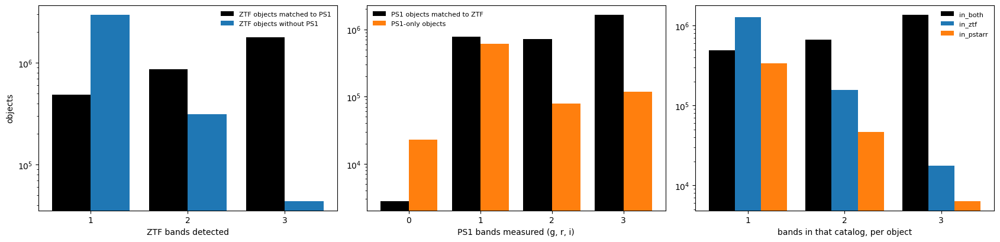

objects with >= 2 bands in the same catalog (the branch requirement): {'in_both': 2039308, 'in_ztf': 174902, 'in_pstarr': 53009}


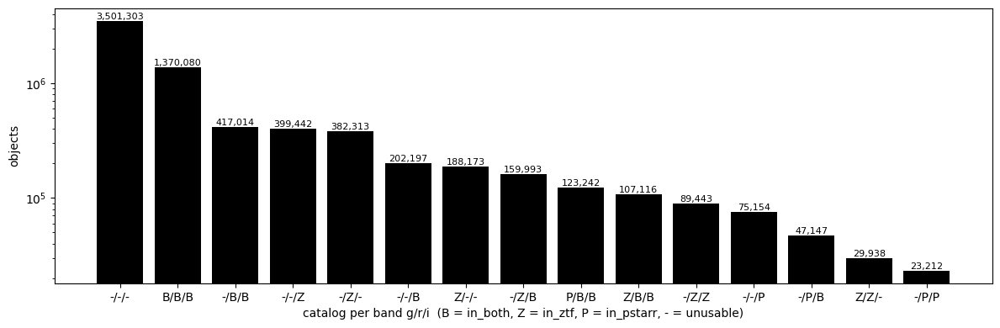

In [ ]:
# band multiplicity: ZTF detections per object (matched / unmatched to PS1) and PS1 measured bands (matched / PS1-only)
nz = sum(src[f'{b}_ztf_det'].astype(int) for b in 'gri'); npb = sum(src[f'{b}_ps1_meas'].astype(int) for b in 'gri')
ncat = {k: sum((src[f'{b}_cat'] == k).astype(int) for b in 'gri') for k in (0, 1, 2)}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for n, sel, lab, c in ((nz, is_ztf & has_ps1, 'ZTF objects matched to PS1', 'k'), (nz, is_ztf & ~has_ps1, 'ZTF objects without PS1', 'C0')):
    axes[0].bar(np.arange(1, 4) + (0.2 if c == 'C0' else -0.2), [((n == k) & sel).sum() for k in (1, 2, 3)], width=0.4, color=c, label=lab)
axes[0].set_xticks([1, 2, 3]); axes[0].set_xlabel('ZTF bands detected'); axes[0].set_ylabel('objects'); axes[0].legend(frameon=False, fontsize=8); axes[0].set_yscale('log')
for n, sel, lab, c in ((npb, has_ps1 & is_ztf, 'PS1 objects matched to ZTF', 'k'), (npb, ~is_ztf, 'PS1-only objects', 'C1')):
    axes[1].bar(np.arange(0, 4) + (0.2 if c == 'C1' else -0.2), [((n == k) & sel).sum() for k in (0, 1, 2, 3)], width=0.4, color=c, label=lab)
axes[1].set_xticks([0, 1, 2, 3]); axes[1].set_xlabel('PS1 bands measured (g, r, i)'); axes[1].legend(frameon=False, fontsize=8); axes[1].set_yscale('log')
for k, (lab, c) in enumerate((('in_both', 'k'), ('in_ztf', 'C0'), ('in_pstarr', 'C1'))):
    axes[2].bar(np.arange(1, 4) + (k - 1) * 0.27, [(ncat[k] == m).sum() for m in (1, 2, 3)], width=0.27, color=c, label=lab)
axes[2].set_xticks([1, 2, 3]); axes[2].set_xlabel('bands in that catalog, per object'); axes[2].legend(frameon=False, fontsize=8); axes[2].set_yscale('log')
plt.tight_layout(); plt.show()
print('objects with >= 2 bands in the same catalog (the branch requirement):', {CAT[k]: int((ncat[k] >= 2).sum()) for k in (0, 1, 2)})

# the per-object pattern of catalogs across g, r, i
pat = pd.Series(['/'.join({0: 'B', 1: 'Z', 2: 'P', -1: '-'}[k] for k in zip(*[src[f'{b}_cat'].values for b in 'gri'])) for _ in [0]][0] if False else ['/'.join({0: 'B', 1: 'Z', 2: 'P', -1: '-'}[src[f'{b}_cat'].values[i]] for b in 'gri') for i in range(len(src))])
top = pat.value_counts().head(15)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(top.index, top.values, color='k'); ax.set_yscale('log'); ax.set_ylabel('objects'); ax.set_xlabel('catalog per band g/r/i  (B = in_both, Z = in_ztf, P = in_pstarr, - = unusable)')
for k, v in enumerate(top.values): ax.text(k, v, f'{v:,}', ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()

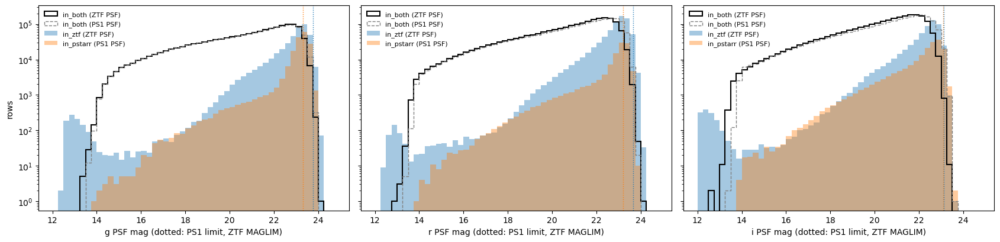

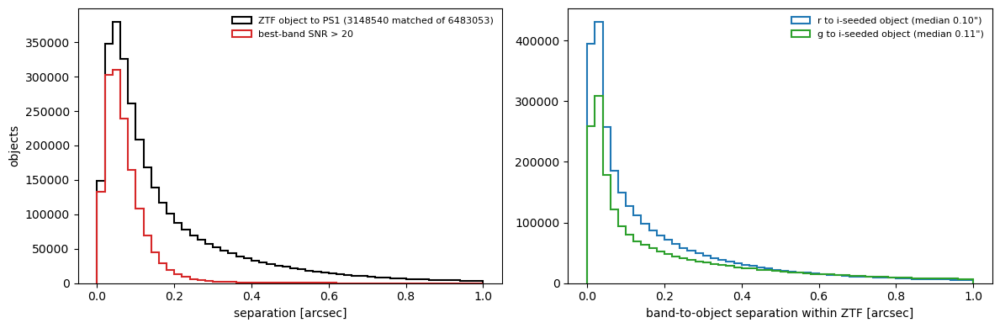

In [ ]:
# magnitude distributions per catalog, per band: the detected side's PSF magnitude
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
bins = np.arange(12, 25, 0.25)
for ax, b in zip(axes, 'gri'):
    cat = src[f'{b}_cat'].values
    ax.hist(src[f'{b}_ztf_psf'][cat == 0], bins=bins, histtype='step', color='k', lw=1.5, label='in_both (ZTF PSF)')
    ax.hist(src[f'{b}_ps1_psf'][cat == 0], bins=bins, histtype='step', color='0.5', lw=1, ls='--', label='in_both (PS1 PSF)')
    ax.hist(src[f'{b}_ztf_psf'][cat == 1], bins=bins, histtype='stepfilled', color='C0', alpha=0.4, label='in_ztf (ZTF PSF)')
    ax.hist(src[f'{b}_ps1_psf'][cat == 2], bins=bins, histtype='stepfilled', color='C1', alpha=0.4, label='in_pstarr (PS1 PSF)')
    ax.axvline(ff.PSTARR_UPPER_LIM[b], color='C1', lw=1, ls=':'); ax.axvline(np.nanmedian(src[f'{b}_ztf_maglim']), color='C0', lw=1, ls=':')
    ax.set_yscale('log'); ax.set_xlabel(f'{b} PSF mag (dotted: PS1 limit, ZTF MAGLIM)'); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('rows')
plt.tight_layout(); plt.show()

# match separations: ZTF object to PS1, and each band to the object within ZTF
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sb = np.linspace(0, 1, 51)
axes[0].hist(obj.ps1_sep.dropna(), bins=sb, histtype='step', color='k', lw=1.5, label=f'ZTF object to PS1 ({obj.matched.sum()} matched of {len(obj)})')
axes[0].hist(obj.ps1_sep[obj.best_snr > 20].dropna(), bins=sb, histtype='step', color='C3', lw=1.5, label='best-band SNR > 20')
axes[0].set_xlabel('separation [arcsec]'); axes[0].set_ylabel('objects'); axes[0].legend(frameon=False, fontsize=8)
for b, c in (('r', 'C0'), ('g', 'C2')):
    s = obj[f'{b}_sep'][(obj[f'{b}_idx'] >= 0) & (obj[f'{b}_sep'] > 0)]
    axes[1].hist(s, bins=sb, histtype='step', color=c, lw=1.5, label=f'{b} to i-seeded object (median {s.median():.2f}")')
axes[1].set_xlabel('band-to-object separation within ZTF [arcsec]'); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

/var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/ipykernel_30202/1615069865.py:10: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout(); plt.show()


/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


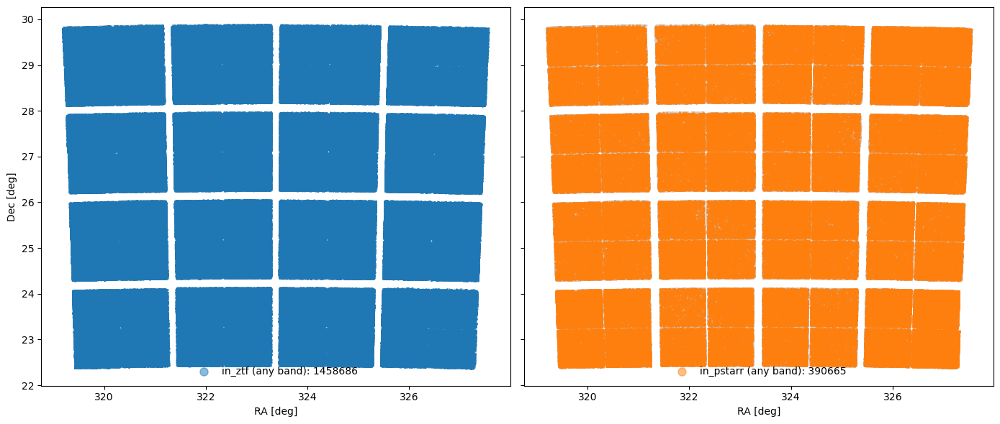

In [ ]:
# where the one-sided rows are: sky positions of in_ztf and in_pstarr rows (any band) over the in_both rows
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
both_any = np.any([src[f'{b}_cat'].values == 0 for b in 'gri'], axis=0)
for ax, k, lab, c in ((axes[0], 1, 'in_ztf (any band)', 'C0'), (axes[1], 2, 'in_pstarr (any band)', 'C1')):
    sel = np.any([src[f'{b}_cat'].values == k for b in 'gri'], axis=0)
    ax.scatter(src.ra[both_any], src.dec[both_any], s=0.3, color='0.8', rasterized=True)
    ax.scatter(src.ra[sel], src.dec[sel], s=1, color=c, alpha=0.5, label=f'{lab}: {sel.sum()}')
    ax.invert_xaxis(); ax.set_xlabel('RA [deg]'); ax.legend(frameon=False, markerscale=8)
axes[0].set_ylabel('Dec [deg]')
plt.tight_layout(); plt.show()

## 2c. The branches

The flowcharts of the three filter chains.

in_both


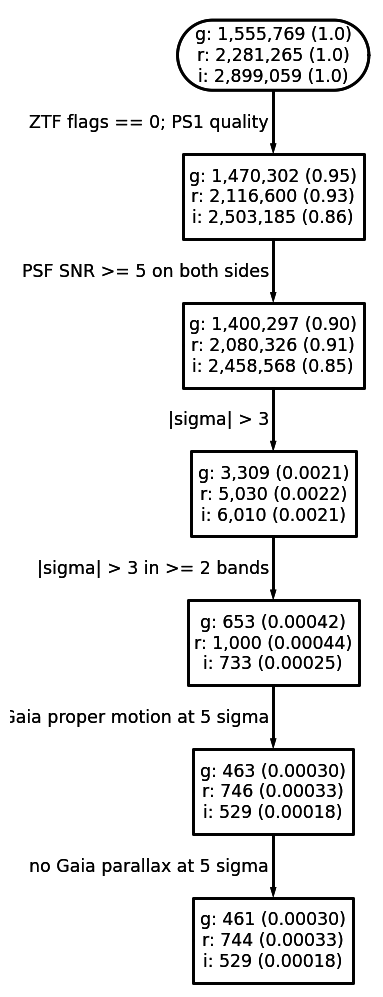

in_ztf


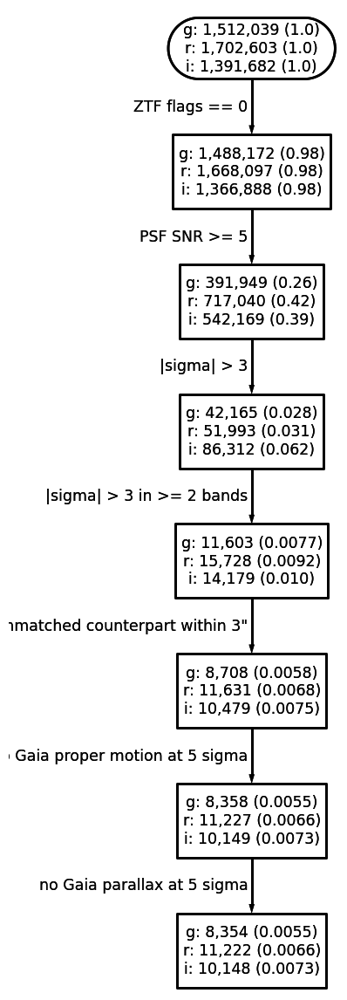

in_pstarr


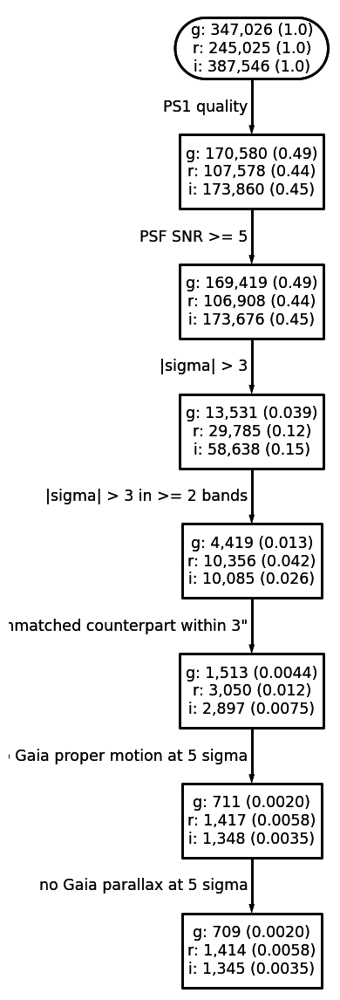

In [ ]:
for name, wf in wfs.items():
    print(name)
    display(wf.flowchart(f'{name} ({FIELD})'))

### What the counterpart step removes

Random examples of rows dropped by "no unmatched counterpart within 3\"" in each one-sided branch: ZTF r cutouts (30"), ZTF objects in blue, PS1 objects in orange, the row itself as the red cross.

in_ztf: 4802 rows dropped by "no unmatched counterpart within 3""


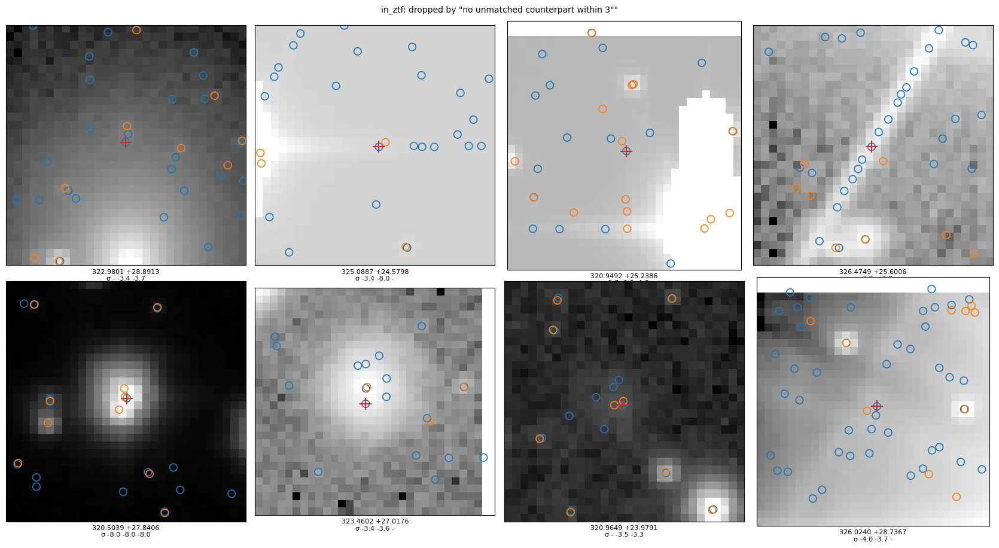

in_pstarr: 7935 rows dropped by "no unmatched counterpart within 3""


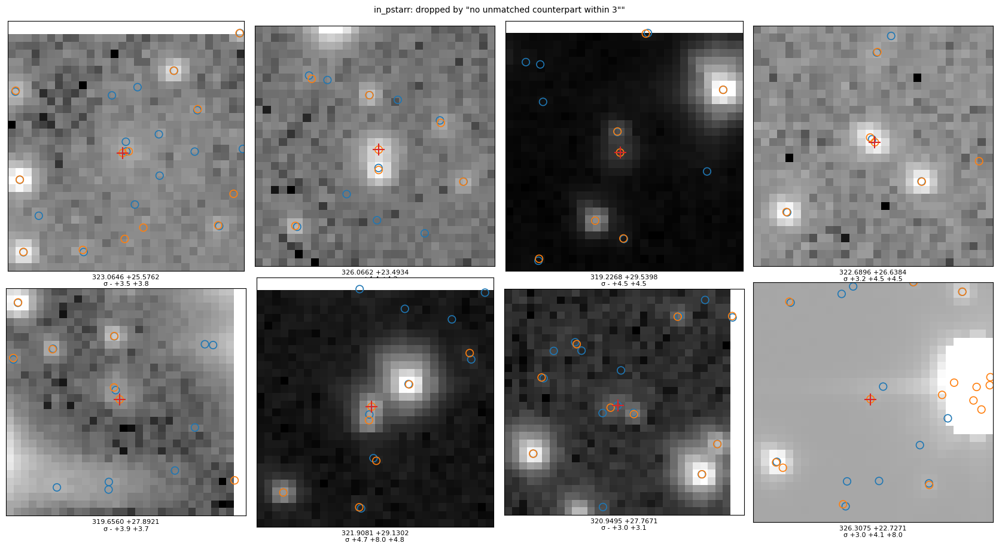

In [ ]:
_imgs = {}
def ztf_image(ccd, qid, b):
    key = (ccd, qid, b)
    if key not in _imgs:
        _imgs[key] = load_ztf_refimg(refimg_path(f'{D}/ztf_data', FIELD, ccd, qid, b))
    return _imgs[key]

def mark_cutouts(rows, title, n=8, size=30):
    rows = rows.head(n); nc = 4; nr = int(np.ceil(len(rows) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(4.2 * nc, 4.6 * nr), squeeze=False); axes = axes.ravel()
    for ax in axes[len(rows):]: ax.set_axis_off()
    for ax, (_, r) in zip(axes, rows.iterrows()):
        im = ztf_image(int(r.ccd), int(r.qid), 'r')
        cut = Cutout2D(im.data, SkyCoord(r.ra * u.deg, r.dec * u.deg), size * u.arcsec, wcs=im.wcs)
        ax.imshow(cut.data, origin='lower', cmap='gray', norm=simple_norm(np.nan_to_num(cut.data), 'log', percent=99.5))
        for cat, col in ((obj, 'C0'), (ps1, 'C1')):
            x, y = cut.wcs.world_to_pixel_values(cat.ra.values, cat.dec.values)
            s = (x > 0) & (x < cut.shape[1]) & (y > 0) & (y < cut.shape[0])
            ax.scatter(x[s], y[s], s=80, facecolors='none', edgecolors=col, lw=1.2)
        x0, y0 = cut.wcs.world_to_pixel_values(r.ra, r.dec); ax.plot(x0, y0, '+', color='C3', ms=14, mew=1.5)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(f'{r.ra:.4f} {r.dec:+.4f}\nσ ' + ' '.join(f'{r[f"{b}_sigma"]:+.1f}' if np.isfinite(r[f'{b}_sigma']) else '-' for b in 'gri'), fontsize=8)
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

for name in ('in_ztf', 'in_pstarr'):
    wf = wfs[name]; label = next(s for s in wf.steps if s.startswith('no unmatched counterpart'))
    dropped = np.any(list(wf.dropped_by(label).values()), axis=0)
    print(f'{name}: {dropped.sum()} rows dropped by "{label}"')
    mark_cutouts(src[dropped].sample(min(8, dropped.sum()), random_state=1), f'{name}: dropped by "{label}"')

## 3. The envelopes

The `in_both` quality sample per band, point sources on PSF Δmag and extended sources on Kron Δmag, with the single envelope built on both; |σ| > 3 points in red.

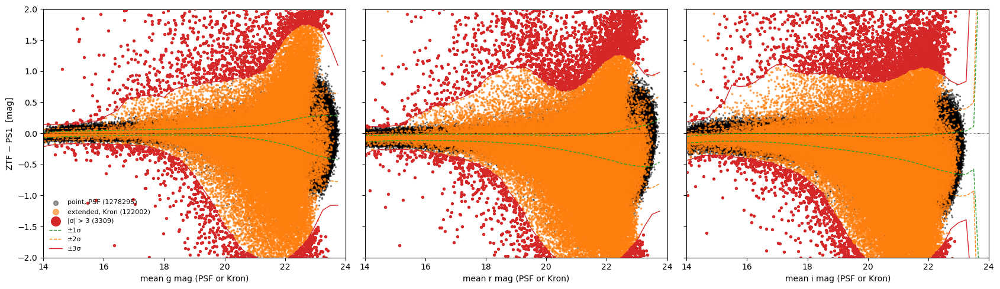

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
levels = [(-3, 'C3'), (-2, 'C1'), (-1, 'C2'), (1, 'C2'), (2, 'C1'), (3, 'C3')]
for ax, b in zip(axes, 'gri'):
    s = src[src[f'{b}_cat'] == 0]; pt = s[f'{b}_point'].values
    mag = (s[f'{b}_ztf_use'].values + s[f'{b}_ps1_use'].values) / 2; d = s[f'{b}_dmag'].values
    ax.scatter(mag[pt], d[pt], s=2, alpha=0.4, color='k', label=f'point, PSF ({pt.sum()})')
    ax.scatter(mag[~pt], d[~pt], s=3, alpha=0.6, color='C1', label=f'extended, Kron ({(~pt).sum()})')
    big = np.abs(s[f'{b}_sigma'].values) > 3
    ax.scatter(mag[big], d[big], s=8, color='C3', label=f'|σ| > 3 ({big.sum()})')
    env = envelopes[b]
    for n, c in levels:
        ax.plot(env.mag_grid, env.get_percentile(env.mag_grid, norm.cdf(n)), color=c, lw=1, ls='-' if abs(n) == 3 else '--', label=f'±{n}σ' if n > 0 else None)
    ax.axhline(0, color='k', lw=0.6, ls=':'); ax.set_xlim(14, 24); ax.set_ylim(-2, 2); ax.set_xlabel(f'mean {b} mag (PSF or Kron)')
    if b == 'g': ax.set_ylabel('ZTF − PS1  [mag]'); ax.legend(frameon=False, fontsize=8, markerscale=4, loc='lower left')
plt.tight_layout(); plt.show()

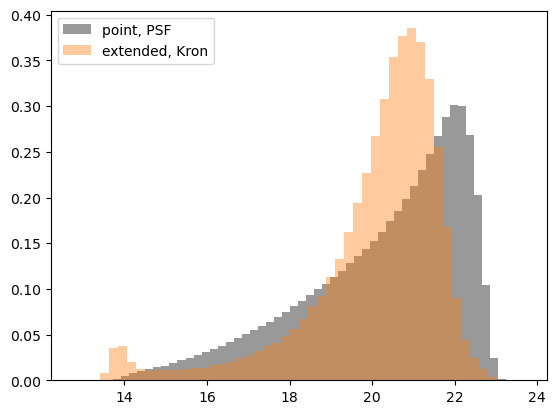

In [ ]:
plt.hist(mag[pt], alpha=0.4, color='k', label='point, PSF', density=True, bins=50); plt.hist(mag[~pt], alpha=0.4, color='C1', label='extended, Kron', density=True, bins=50); plt.legend(); plt.show()

### 3a. Envelope variants

The same `in_both` quality sample (both sides detected, quality cuts, SNR ≥ 5), with the envelope built four ways: PSF magnitudes of point sources only, Kron magnitudes of extended sources only, PSF magnitudes of everything, and Kron magnitudes of everything. Point/extended is the PSF − Kron morphology rule used by the pipeline. Rows without a Kron magnitude on both sides are left out of the Kron variants. Scatter plots show at most 300,000 random points per panel; the envelopes use every row.

In [ ]:
from astropy.table import Table
LEVELS = [(-3, 'C3'), (-2, 'C1'), (-1, 'C2'), (1, 'C2'), (2, 'C1'), (3, 'C3')]
rng = np.random.default_rng(0)

def envelope_variant(kind, which, title):
    """kind: 'psf' or 'kron'; which: 'point', 'extended' or 'all'."""
    tabs, rows = {}, {}
    for b in 'gri':
        s = src[src[f'{b}_cat'] == 0]
        point = s[f'{b}_point'].values
        if which != 'all':
            s, point = s[point == (which == 'point')], point[point == (which == 'point')]
        z, ze = s[f'{b}_ztf_{kind}'].values, s[f'{b}_ztf_{kind}_err'].values
        p, pe = s[f'{b}_ps1_{kind}'].values, s[f'{b}_ps1_{kind}_err'].values
        ok = np.isfinite(z) & np.isfinite(p)
        z, ze, p, pe, pt = z[ok], ze[ok], p[ok], pe[ok], point[ok]
        tabs[b] = Table({f'ZTF_{b}PSFMag': z, f'ZTF_{b}PSFMagErr': ze, f'PSTARR_{b}PSFMag': p, f'PSTARR_{b}PSFMagErr': pe})
        rows[b] = ((z + p) / 2, z - p, pt)
    env = ff.kde_envelopes(tabs)
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
    for ax, b in zip(axes, 'gri'):
        mag, d, pt = rows[b]
        show = rng.choice(len(d), min(len(d), 300_000), replace=False) if len(d) else np.array([], int)
        m, dd, pp = mag[show], d[show], pt[show]
        ax.scatter(m[pp], dd[pp], s=1, alpha=0.3, color='k', rasterized=True, label=f'point ({pt.sum():,})')
        ax.scatter(m[~pp], dd[~pp], s=1, alpha=0.4, color='C1', rasterized=True, label=f'extended ({(~pt).sum():,})')
        e = env[b]
        for n, c in LEVELS:
            ax.plot(e.mag_grid, e.get_percentile(e.mag_grid, norm.cdf(n)), color=c, lw=1.2, ls='-' if abs(n) == 3 else '--', label=f'±{n}σ' if n > 0 else None)
        ax.axhline(0, color='k', lw=0.6, ls=':'); ax.set_xlim(14, 24); ax.set_ylim(-2, 2)
        ax.set_xlabel(f'mean {b} {kind.upper()} mag')
        if b == 'g': ax.set_ylabel(f'ZTF − PS1 {kind.upper()}  [mag]'); ax.legend(frameon=False, fontsize=8, markerscale=6, loc='lower left')
    fig.suptitle(title, fontsize=11); plt.tight_layout(); plt.show()
    return env

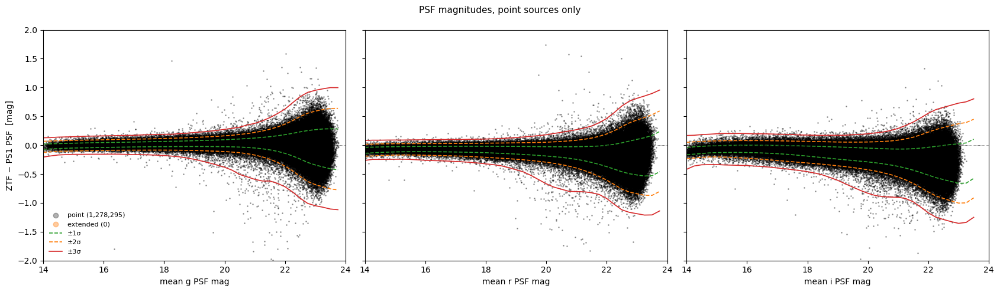

In [ ]:
env_psf_point = envelope_variant('psf', 'point', 'PSF magnitudes, point sources only')

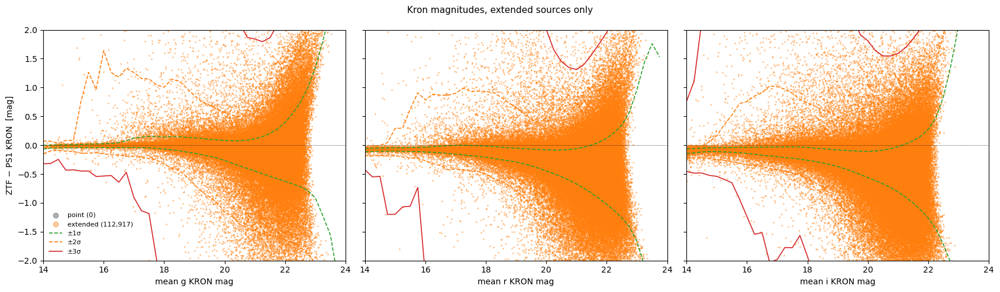

In [ ]:
env_kron_ext = envelope_variant('kron', 'extended', 'Kron magnitudes, extended sources only')

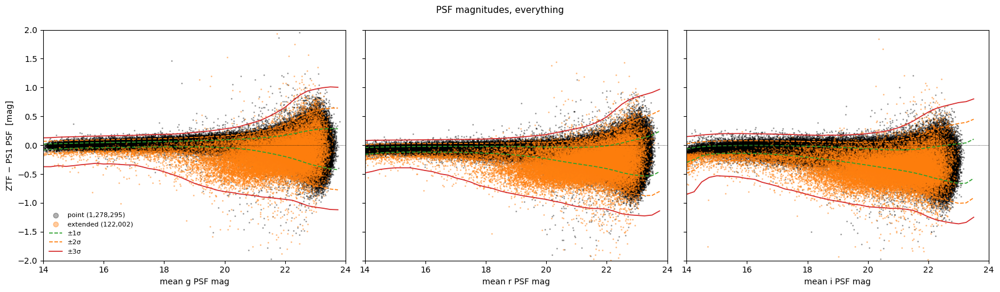

In [ ]:
env_psf_all = envelope_variant('psf', 'all', 'PSF magnitudes, everything')

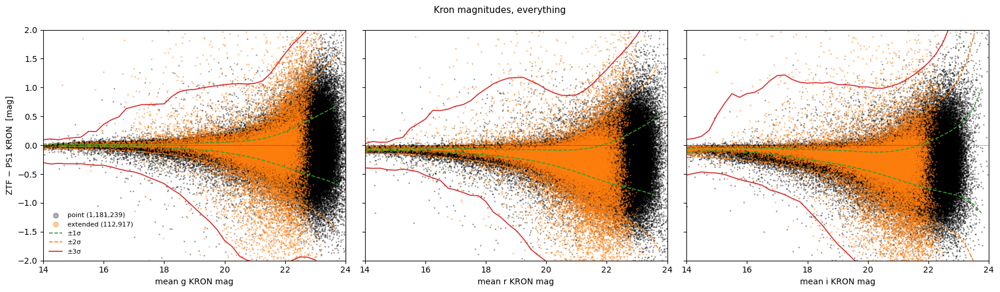

In [ ]:
env_kron_all = envelope_variant('kron', 'all', 'Kron magnitudes, everything')

#### The high-scatter extended sources: the two surveys disagree about morphology

Extended `in_both` sources judged on a clean Kron aperture (under `ff.KRON_MAX_MASKED` masked), split into those beyond 3σ and the rest. For normal galaxies ZTF's and PS1's PSF − Kron agree; the outliers sit on two arms where one survey calls the object point-like and the other very extended, and only the Kron magnitude of the "extended" side moves (the PSF Δmag barely does). σ > 3 (ZTF Kron fainter) are mostly faint low-surface-brightness galaxies whose outskirts PS1 (deeper, sharper) puts in its Kron aperture while ZTF sees only the core, its Kron radius at the point-source floor; σ < −3 (ZTF Kron brighter) are mostly pairs PS1 resolves but DAOPhot treats as one source, and sources on bright-star halos or uneven background.

n   share ZTF PSF−Kron PS1 PSF−Kron  \
band group                                                                   
g    σ > 3 (ZTF Kron fainter)        806   1.03%        -0.24        +1.07   
     σ < −3 (ZTF Kron brighter)      224   0.29%        +0.95        -0.11   
     rest                         77,271  98.63%        +0.40        +0.56   
r    σ > 3 (ZTF Kron fainter)      1,061   0.80%        -0.16        +1.03   
     σ < −3 (ZTF Kron brighter)      384   0.29%        +0.96        -0.29   
     rest                        130,607  98.58%        +0.36        +0.46   
i    σ > 3 (ZTF Kron fainter)        869   0.55%        -0.19        +0.95   
     σ < −3 (ZTF Kron brighter)      361   0.23%        +0.91        -0.07   
     rest                        152,539  96.75%        +0.28        +0.44   

                                Kron Δ  PSF Δ Kron |Δ| > PSF |Δ| + 0.3  
band group                                                              
g    σ > 3 (ZTF Kron fainter)    +1.84  +0.41                     100%  
     σ < −3 (ZTF Kron brighter)  -1.83  -0.26                      70%  
     rest                        -0.03  -0.20                      15%  
r    σ > 3 (ZTF Kron fainter)    +1.46  +0.27                      99%  
     σ < −3 (ZTF Kron brighter)  -2.01  -0.40                      76%  
     rest                        -0.20  -0.35                      11%  
i    σ > 3 (ZTF Kron fainter)    +1.30  +0.16                      99%  
     σ < −3 (ZTF Kron brighter)  -1.99  -0.53                      73%  
     rest                        -0.20  -0.41                       6%

point sources on PSF beyond 3σ, for comparison: {'g': '0.02%', 'r': '0.01%', 'i': '0.01%'}
r-band outliers also |σ| > 3 with the same sign in g: 6%  (judged in g: 46%)
r-band outliers also |σ| > 3 with the same sign in i: 6%  (judged in i: 97%)


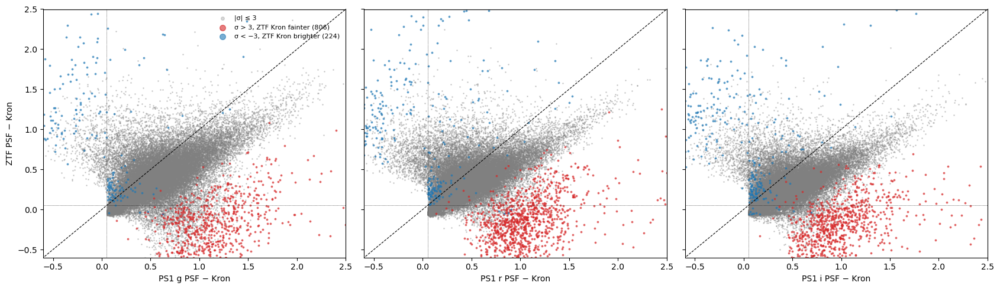

In [ ]:
mad = lambda x: 1.4826 * np.nanmedian(np.abs(x - np.nanmedian(x)))
rows, arms = [], {}
for b in 'gri':
    s = src[(src[f'{b}_cat'] == 0) & src[f'{b}_use_kron'] & ~src[f'{b}_kron_contaminated']]
    zpk, ppk = s[f'{b}_ztf_psf'] - s[f'{b}_ztf_kron'], s[f'{b}_ps1_psf'] - s[f'{b}_ps1_kron']
    dk, dp, sig = s[f'{b}_dmag'], s[f'{b}_ztf_psf'] - s[f'{b}_ps1_psf'], s[f'{b}_sigma']
    arms[b] = (s, zpk, ppk, sig)
    for lab, sel in (('σ > 3 (ZTF Kron fainter)', sig > 3), ('σ < −3 (ZTF Kron brighter)', sig < -3), ('rest', np.abs(sig) <= 3)):
        rows.append({'band': b, 'group': lab, 'n': f'{sel.sum():,}', 'share': f'{100*sel.mean():.2f}%',
                     'ZTF PSF−Kron': f'{zpk[sel].median():+.2f}', 'PS1 PSF−Kron': f'{ppk[sel].median():+.2f}',
                     'Kron Δ': f'{dk[sel].median():+.2f}', 'PSF Δ': f'{dp[sel].median():+.2f}',
                     'Kron |Δ| > PSF |Δ| + 0.3': f'{100*np.mean(np.abs(dk[sel]) > np.abs(dp[sel]) + 0.3):.0f}%'})
display(pd.DataFrame(rows).set_index(['band', 'group']))
pt_rate = {b: 100 * np.mean(np.abs(src[f'{b}_sigma'][(src[f'{b}_cat'] == 0) & src[f'{b}_point']]) > 3) for b in 'gri'}
print('point sources on PSF beyond 3σ, for comparison:', {b: f'{v:.2f}%' for b, v in pt_rate.items()})

# multi-band: an r-band outlier is also beyond 3σ, same sign, in g / i?
s, zpk, ppk, sig = arms['r']; out = s.index[np.abs(sig) > 3]
for bb in 'gi':
    other = src.loc[out, f'{bb}_sigma']
    print(f'r-band outliers also |σ| > 3 with the same sign in {bb}: {100*np.mean((np.abs(other) > 3) & (np.sign(other) == np.sign(sig[out]))):.0f}%  (judged in {bb}: {100*np.mean(np.isfinite(other)):.0f}%)')

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for ax, b in zip(axes, 'gri'):
    s, zpk, ppk, sig = arms[b]; o = np.abs(sig) > 3
    rest = np.flatnonzero(~o.values); rest = rng.choice(rest, min(len(rest), 40_000), replace=False)
    ax.scatter(ppk.values[rest], zpk.values[rest], s=1, alpha=0.3, color='0.5', rasterized=True, label='|σ| ≤ 3')
    ax.scatter(ppk[o & (sig > 0)], zpk[o & (sig > 0)], s=3, alpha=0.6, color='C3', label=f'σ > 3, ZTF Kron fainter ({(o & (sig > 0)).sum():,})')
    ax.scatter(ppk[o & (sig < 0)], zpk[o & (sig < 0)], s=3, alpha=0.6, color='C0', label=f'σ < −3, ZTF Kron brighter ({(o & (sig < 0)).sum():,})')
    ax.plot([-1, 3], [-1, 3], 'k--', lw=0.8); ax.axvline(ff.PSF_KRON_CUT, color='k', lw=0.5, ls=':'); ax.axhline(ff.PSF_KRON_CUT, color='k', lw=0.5, ls=':')
    ax.set_xlim(-0.6, 2.5); ax.set_ylim(-0.6, 2.5); ax.set_xlabel(f'PS1 {b} PSF − Kron')
    if b == 'g': ax.set_ylabel('ZTF PSF − Kron'); ax.legend(frameon=False, fontsize=8, markerscale=4, loc='upper right')
plt.tight_layout(); plt.show()

#### One morphology per object: per band, vote, or a multiband statistic

The high-scatter Kron sources are almost never outliers in more than one band. Two object-level morphology rules, as `assign_catalogs_dev(morphology=...)`, against the per-band rule (`'combined'`, used in sections 2–3), all with clean-aperture Kron only (`kron_policy='psf'`):

- **vote**: extended if the per-band PSF − Kron statistic exceeds 3σ in ≥ 2 of the measured bands (the one band if only one is measured);
- **multiband**: extended if the inverse-variance combination over all bands and both catalogs exceeds 3σ.

Each row is the pipeline's own envelope (`assign_catalogs` → `envelope_tables` → `kde_envelopes` → `annotate_sigma`).

/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "pmsafe" yielded 1466991 of "distance overridden (Note 6)", 133 of "binary logical OR of the above warnings"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


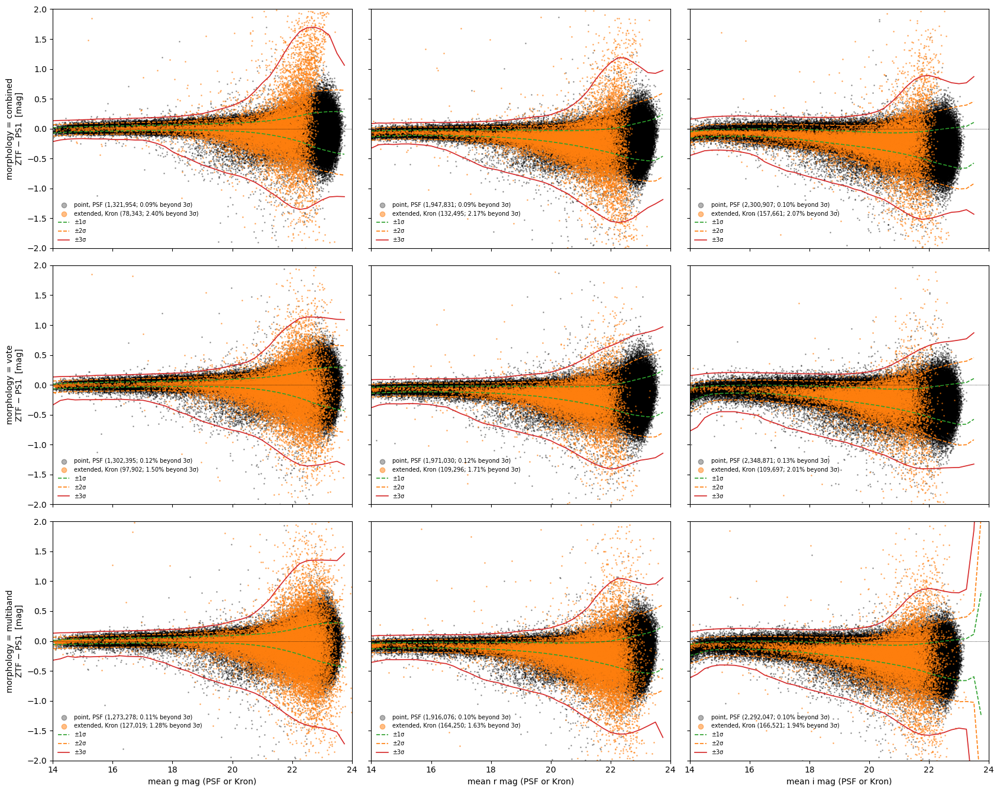

In [ ]:
morph_runs = {}
for morph in ('combined', 'vote', 'multiband'):
    s_ = assign_catalogs_dev(base, kron_policy='psf', morphology=morph)
    env_ = ff.kde_envelopes(ff.envelope_tables(s_)); s_ = ff.annotate_sigma(s_, env_)
    morph_runs[morph] = (s_[[f'{b}_{c}' for b in 'gri' for c in ('cat', 'use_kron', 'ztf_use', 'ps1_use', 'sigma')]].copy(), env_)
    del s_

fig, axes = plt.subplots(3, 3, figsize=(17, 13.5), sharex=True, sharey=True)
for row, (morph, (s_, env_)) in enumerate(morph_runs.items()):
    for ax, b in zip(axes[row], 'gri'):
        s = s_[s_[f'{b}_cat'] == 0]
        mag = (s[f'{b}_ztf_use'] + s[f'{b}_ps1_use']).values / 2; d = (s[f'{b}_ztf_use'] - s[f'{b}_ps1_use']).values
        kr, sig = s[f'{b}_use_kron'].values, s[f'{b}_sigma'].values
        show = rng.random(len(s)) < min(1, 300_000 / max(len(s), 1))
        ax.scatter(mag[show & ~kr], d[show & ~kr], s=1, alpha=0.3, color='k', rasterized=True, label=f'point, PSF ({(~kr).sum():,}; {100*np.mean(np.abs(sig[~kr]) > 3):.2f}% beyond 3σ)')
        ax.scatter(mag[show & kr], d[show & kr], s=1, alpha=0.5, color='C1', rasterized=True, label=f'extended, Kron ({kr.sum():,}; {100*np.mean(np.abs(sig[kr]) > 3):.2f}% beyond 3σ)')
        e = env_[b]
        for n, c in LEVELS:
            ax.plot(e.mag_grid, e.get_percentile(e.mag_grid, norm.cdf(n)), color=c, lw=1.2, ls='-' if abs(n) == 3 else '--', label=f'±{n}σ' if n > 0 else None)
        ax.axhline(0, color='k', lw=0.6, ls=':'); ax.set_xlim(14, 24); ax.set_ylim(-2, 2)
        ax.legend(frameon=False, fontsize=7, markerscale=6, loc='lower left')
        if row == 2: ax.set_xlabel(f'mean {b} mag (PSF or Kron)')
        if b == 'g': ax.set_ylabel(f'morphology = {morph}\nZTF − PS1  [mag]')
plt.tight_layout(); plt.show()

#### A multi-band rule on Δmag

A candidate already needs |σ| > 3 in ≥ 2 bands (a vote), but not with the same sign. Below, for the per-band envelope: the in_both objects with |σ| > 3 in ≥ 2 bands, split by whether the signs agree, and a combined three-band significance, Stouffer's Σσ/√n over the measured bands, against that rule (σ is capped at ±8, so the combined value saturates near 8√n/√n).

|σ| > 3 in >= 2 bands: 953; mixed signs: 31 (3%), of which 71% involve a Kron-judged band


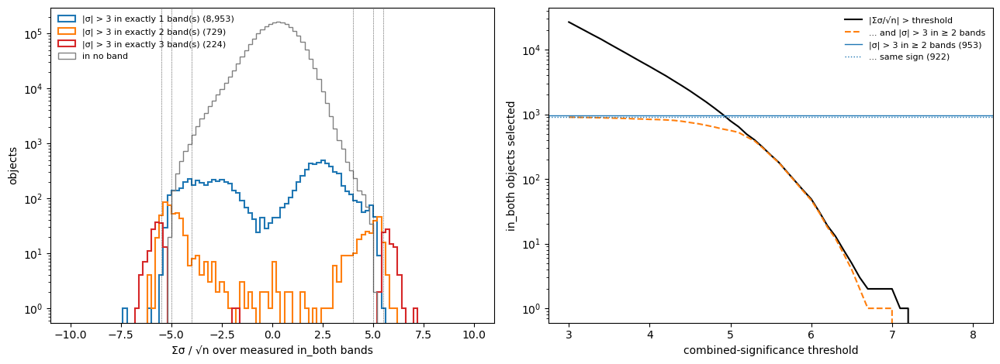

In [ ]:
s_ = morph_runs['combined'][0]
S = np.array([s_[f'{b}_sigma'].values for b in 'gri']); C = np.array([(s_[f'{b}_cat'] == 0).values for b in 'gri'])
K = np.array([s_[f'{b}_use_kron'].values for b in 'gri'])
big = (np.abs(S) > 3) & C; two = big.sum(0) >= 2
pos, neg = ((S > 3) & C).sum(0), ((S < -3) & C).sum(0); mixed = two & (pos >= 1) & (neg >= 1)
print(f'|σ| > 3 in >= 2 bands: {two.sum():,}; mixed signs: {mixed.sum():,} ({100*mixed.sum()/max(two.sum(), 1):.0f}%), of which {100*np.mean((K & big)[:, mixed].any(0)):.0f}% involve a Kron-judged band')
use = C & np.isfinite(S); n = use.sum(0)
stouffer = np.where(n >= 2, np.where(use, S, 0.0).sum(0) / np.sqrt(np.maximum(n, 1)), np.nan)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
nb_ = np.where(use, np.abs(S) > 3, False).sum(0)
for k, c in ((1, 'C0'), (2, 'C1'), (3, 'C3')):
    sel = (n >= 2) & (nb_ == k)
    axes[0].hist(stouffer[sel], bins=np.linspace(-10, 10, 101), histtype='step', lw=1.5, color=c, label=f'|σ| > 3 in exactly {k} band(s) ({sel.sum():,})')
axes[0].hist(stouffer[(n >= 2) & (nb_ == 0)], bins=np.linspace(-10, 10, 101), histtype='step', lw=1, color='0.5', label='in no band')
axes[0].set_yscale('log'); axes[0].set_xlabel('Σσ / √n over measured in_both bands'); axes[0].set_ylabel('objects'); axes[0].legend(frameon=False, fontsize=8)
for thr in (4, 5, 5.5):
    axes[0].axvline(thr, color='k', lw=0.5, ls=':'); axes[0].axvline(-thr, color='k', lw=0.5, ls=':')
thr = np.linspace(3, 8, 51)
axes[1].plot(thr, [np.sum(np.abs(stouffer) > t) for t in thr], 'k-', label='|Σσ/√n| > threshold')
axes[1].plot(thr, [np.sum((np.abs(stouffer) > t) & two) for t in thr], 'C1--', label='... and |σ| > 3 in ≥ 2 bands')
axes[1].axhline(two.sum(), color='C0', lw=1, label=f'|σ| > 3 in ≥ 2 bands ({two.sum():,})'); axes[1].axhline((two & ~mixed).sum(), color='C0', lw=1, ls=':', label=f'... same sign ({(two & ~mixed).sum():,})')
axes[1].set_yscale('log'); axes[1].set_xlabel('combined-significance threshold'); axes[1].set_ylabel('in_both objects selected'); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### 3b. The extended in_both sources

What the r-band `in_both` sources called extended look like: their magnitudes, PS1 EXT bit, Kron Δmag and how much of the ZTF Kron aperture was masked for neighbours; where they were in the old pipeline (its per-quadrant `r_associated.hdf5` tables from Cannon, copied to `Data/fields/000643/old_pipeline/`, matched at 1"); and cutouts with our ZTF Kron aperture drawn.

In [ ]:
from astropy.table import Table, vstack
import glob
from scipy.spatial import cKDTree
b = 'r'
r_cat = bands[b]
both = src[src[f'{b}_cat'] == 0].copy()
ri = obj[f'{b}_idx'].values[both.ztf_idx.values]
both['kron_masked'] = r_cat.zkron_masked.values[ri]; both['kron_rap'] = r_cat.zkron_rap.values[ri]
both['ps1_ext'] = (ps1.qualityFlag.astype(int).values[both.ps1_idx.values] & 1) != 0
both['dmag_kron'] = both[f'{b}_ztf_kron'] - both[f'{b}_ps1_kron']; both['dmag_psf'] = both[f'{b}_ztf_psf'] - both[f'{b}_ps1_psf']
ext, pt = both[~both[f'{b}_point']], both[both[f'{b}_point']]
print(f'r in_both: {len(both):,} rows; extended {len(ext):,} ({100*len(ext)/len(both):.1f}%); of the extended, PS1 EXT bit set for {100*ext.ps1_ext.mean():.0f}% (point sources: {100*pt.ps1_ext.mean():.1f}%)')

# the old pipeline's r-band rows for the whole field
old = vstack([Table.read(f, path='data')['ra', 'dec', 'Catalog_Flag', 'ZTF_rPSFMag', 'PSTARR_rPSFMag'] for f in sorted(glob.glob(f'{D}/fields/000643/old_pipeline/r_*.hdf5'))]).to_pandas()
def xyz(ra, dec):
    r, d = np.radians(ra), np.radians(dec); return np.c_[np.cos(d) * np.cos(r), np.cos(d) * np.sin(r), np.sin(d)]
tree = cKDTree(xyz(old.ra.values, old.dec.values))
OLD = {0: 'old in_both', 1: 'old ZTF only', 2: 'old PS1 only', 3: 'old out of coverage', -1: 'not in old tables'}
def old_bucket(df):
    d, j = tree.query(xyz(df.ra.values, df.dec.values), distance_upper_bound=2 * np.sin(np.radians(1 / 3600) / 2))
    return np.where(np.isfinite(d), old.Catalog_Flag.values[np.clip(j, 0, len(old) - 1)], -1)
ext['old'] = old_bucket(ext); pt_s = pt.sample(200_000, random_state=0); pt_s['old'] = old_bucket(pt_s)
tab = pd.DataFrame({'extended (all)': ext.old.value_counts(normalize=True), 'point (sample)': pt_s.old.value_counts(normalize=True)}).rename(index=OLD).fillna(0) * 100
display(tab.round(1).astype(str) + '%')
print('extended sources, Kron dmag robust scatter by old bucket (19-21 mag):')
mag = (ext[f'{b}_ztf_use'] + ext[f'{b}_ps1_use']) / 2; mid = (mag > 19) & (mag < 21)
mad = lambda x: 1.4826 * np.median(np.abs(x - np.median(x)))
for k, n in OLD.items():
    s = ext[mid & (ext.old == k)]
    if len(s) > 50: print(f'  {n:22s} n={len(s):6d}  Kron dmag median {s.dmag_kron.median():+.3f}  scatter {mad(s.dmag_kron):.3f}')

r in_both: 2,080,326 rows; extended 233,545 (11.2%); of the extended, PS1 EXT bit set for 56% (point sources: 2.3%)


/var/folders/2f/vnb6fr7n7g32fwlgp_k3l3sc0000gn/T/ipykernel_32858/4154766514.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ext['old'] = old_bucket(ext); pt_s = pt.sample(200_000, random_state=0); pt_s['old'] = old_bucket(pt_s)


,extended (all),point (sample)
old,,
old in_both,83.1%,85.6%
old PS1 only,14.3%,11.7%
old out of coverage,2.3%,2.7%
old ZTF only,0.3%,0.1%
not in old tables,0.0%,0.0%


extended sources, Kron dmag robust scatter by old bucket (19-21 mag):
  old in_both            n= 79861  Kron dmag median -0.225  scatter nan
  old ZTF only           n=    71  Kron dmag median -0.300  scatter nan
  old PS1 only           n=  9742  Kron dmag median -0.228  scatter nan
  old out of coverage    n=  2248  Kron dmag median -0.224  scatter nan


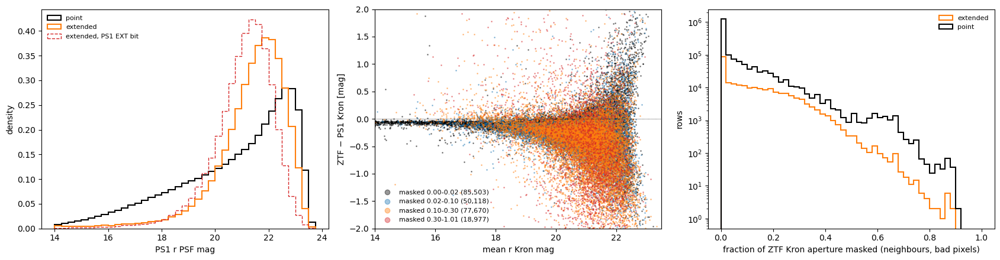

In [ ]:
# what they look like statistically: magnitudes, Kron dmag against masked fraction, PS1 EXT bit
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
bins = np.arange(14, 24, 0.25)
axes[0].hist(pt[f'{b}_ps1_psf'], bins=bins, histtype='step', color='k', lw=1.5, density=True, label='point')
axes[0].hist(ext[f'{b}_ps1_psf'], bins=bins, histtype='step', color='C1', lw=1.5, density=True, label='extended')
axes[0].hist(ext[f'{b}_ps1_psf'][ext.ps1_ext], bins=bins, histtype='step', color='C3', lw=1, ls='--', density=True, label='extended, PS1 EXT bit')
axes[0].set_xlabel('PS1 r PSF mag'); axes[0].set_ylabel('density'); axes[0].legend(frameon=False, fontsize=8)
for lo, hi, c in ((0, 0.02, 'k'), (0.02, 0.1, 'C0'), (0.1, 0.3, 'C1'), (0.3, 1.01, 'C3')):
    s = ext[(ext.kron_masked >= lo) & (ext.kron_masked < hi)]
    axes[1].scatter(((s[f'{b}_ztf_kron'] + s[f'{b}_ps1_kron']) / 2)[::5], s.dmag_kron[::5], s=1, alpha=0.4, color=c, rasterized=True, label=f'masked {lo:.2f}-{hi:.2f} ({len(s):,})')
axes[1].set_xlim(14, 23.5); axes[1].set_ylim(-2, 2); axes[1].axhline(0, color='k', lw=0.6, ls=':'); axes[1].set_xlabel('mean r Kron mag'); axes[1].set_ylabel('ZTF − PS1 Kron [mag]'); axes[1].legend(frameon=False, fontsize=8, markerscale=6)
axes[2].hist(ext.kron_masked, bins=np.linspace(0, 1, 51), histtype='step', color='C1', lw=1.5, label='extended')
axes[2].hist(pt.kron_masked, bins=np.linspace(0, 1, 51), histtype='step', color='k', lw=1.5, label='point')
axes[2].set_yscale('log'); axes[2].set_xlabel('fraction of ZTF Kron aperture masked (neighbours, bad pixels)'); axes[2].set_ylabel('rows'); axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

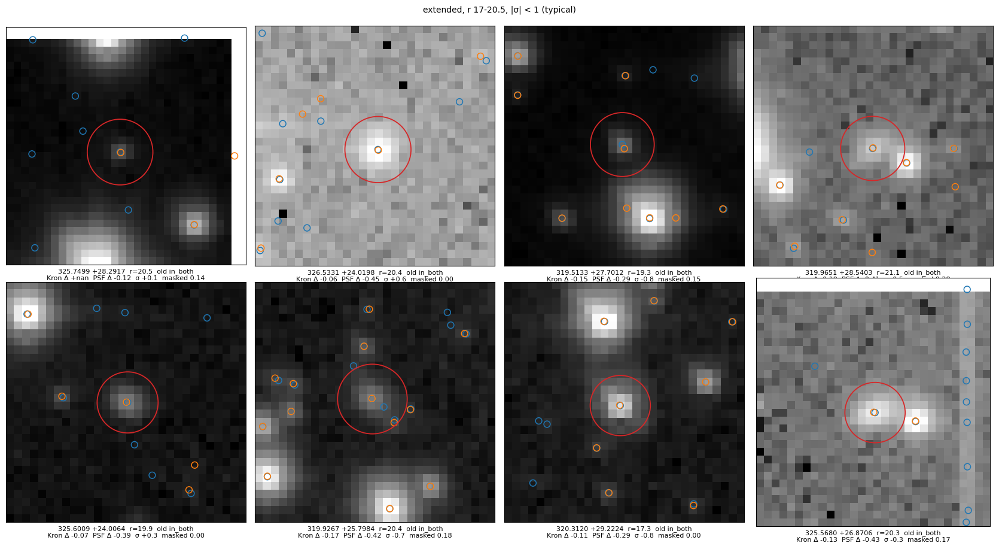

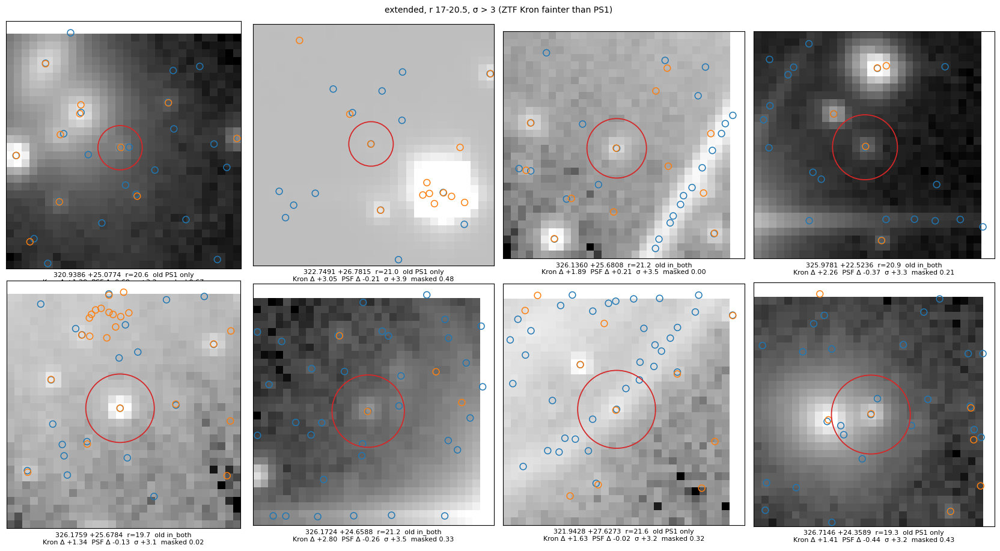

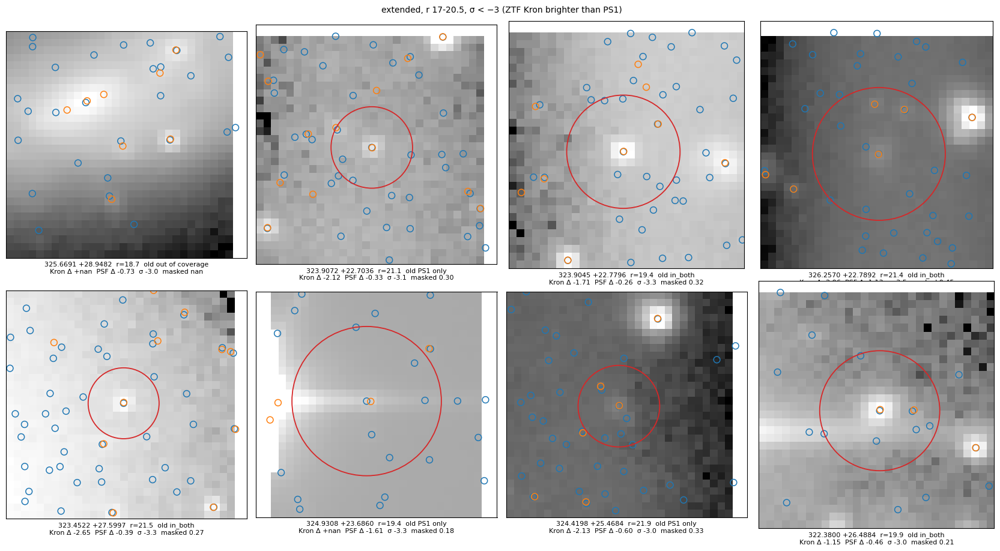

In [ ]:
# cutouts: ZTF r, 30", ZTF objects blue, PS1 objects orange, our ZTF Kron aperture as the red circle
from matplotlib.patches import Circle
def ext_cutouts(rows, title, size=30):
    rows = rows.head(8); fig, axes = plt.subplots(2, 4, figsize=(16.8, 9.2)); axes = axes.ravel()
    for ax in axes[len(rows):]: ax.set_axis_off()
    for ax, (_, r) in zip(axes, rows.iterrows()):
        im = ztf_image(int(r.ccd), int(r.qid), 'r')
        cut = Cutout2D(im.data, SkyCoord(r.ra * u.deg, r.dec * u.deg), size * u.arcsec, wcs=im.wcs)
        ax.imshow(cut.data, origin='lower', cmap='gray', norm=simple_norm(np.nan_to_num(cut.data), 'log', percent=99.5))
        for cat, col in ((obj, 'C0'), (ps1, 'C1')):
            x, y = cut.wcs.world_to_pixel_values(cat.ra.values, cat.dec.values)
            s = (x > 0) & (x < cut.shape[1]) & (y > 0) & (y < cut.shape[0])
            ax.scatter(x[s], y[s], s=60, facecolors='none', edgecolors=col, lw=1.1)
        x0, y0 = cut.wcs.world_to_pixel_values(r.ra, r.dec)
        ax.add_patch(Circle((x0, y0), r.kron_rap / im.pixel_scale, fill=False, color='C3', lw=1.3))
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_xlabel(f'{r.ra:.4f} {r.dec:+.4f}  r={r[f"{b}_ps1_psf"]:.1f}  {OLD[int(r.old)] if pd.notna(r.get('old', np.nan)) else ''}\nKron Δ {r.dmag_kron:+.2f}  PSF Δ {r.dmag_psf:+.2f}  σ {r[f"{b}_sigma"]:+.1f}  masked {r.kron_masked:.2f}', fontsize=8)
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

e1720 = ext[(mag > 17) & (mag < 20.5)]
ext_cutouts(e1720[np.abs(e1720[f'{b}_sigma']) < 1].sample(8, random_state=0), 'extended, r 17-20.5, |σ| < 1 (typical)')
ext_cutouts(e1720[e1720[f'{b}_sigma'] > 3].sample(8, random_state=0), 'extended, r 17-20.5, σ > 3 (ZTF Kron fainter than PS1)')
ext_cutouts(e1720[e1720[f'{b}_sigma'] < -3].sample(8, random_state=0), 'extended, r 17-20.5, σ < −3 (ZTF Kron brighter than PS1)')

### 3c. What the extended population is

The r-band extended `in_both` sources from 3b against a random 200,000 point sources for comparison:

1. **Catalog crossmatch** with the pipeline's own local catalogs (`Source_Analysis.catalogs`: SDSS DR20 spectra, DESI DR1 redshifts, SIMBAD, AGN-DB; nearest within 2", as in `enrich_combined_tabs.py`), each catalog pre-loaded with only the rows inside the field so the matching stays in memory, plus the Gaia match already on the object table.
2. **Location**: distance to the nearest bright star (PS1 r PSF < 14 in the field) and the masked fraction of the ZTF Kron aperture, against the Kron Δmag.
3. **Cutouts** per magnitude bin and per catalog class.

In [ ]:
from Source_Analysis.catalogs import sdss as cat_sdss, desi as cat_desi, simbad as cat_simbad, agn as cat_agn
XM = f'{D}/fields/000643/xmatch_inboth_r.parquet'
pt_sample = pt.sample(200_000, random_state=0)
xm_in = pd.concat([ext.assign(sample='extended'), pt_sample.assign(sample='point')])
if os.path.exists(XM):
    xm = pd.read_parquet(XM)
else:
    box = [('ra', '>=', src.ra.min() - 0.1), ('ra', '<=', src.ra.max() + 0.1), ('dec', '>=', src.dec.min() - 0.1), ('dec', '<=', src.dec.max() + 0.1)]
    parts = []
    for mod in (cat_sdss, cat_desi, cat_simbad, cat_agn):
        lc = mod._CATALOG
        df = pd.read_parquet(lc.parquet_path, filters=box)
        lc._frames[False] = df.reset_index(drop=True)
        lc._frames[True] = (df[lc.row_filter(df)] if lc.row_filter is not None else df).reset_index(drop=True)
        lc._coords.clear()
        res = mod.cone_search_many(xm_in.ra.values, xm_in.dec.values)
        print(f'{lc.prefix}: {len(df):,} catalog rows in the field box; matched {res[f"{lc.prefix}_matched"].mean()*100:.2f}% of the sample')
        parts.append(res.reset_index(drop=True))
        lc._frames.clear(); lc._coords.clear()
    xm = pd.concat([xm_in[['ra', 'dec', 'sample']].reset_index(drop=True)] + parts, axis=1)
    xm.to_parquet(XM)
xm.index = xm_in.index
xm['gaia_star'] = (xm_in.gaia_parallax_over_error >= 5) | (xm_in.gaia_pm_sig >= 5)
xm['gaia_matched'] = np.isfinite(xm_in.gaia_sep_arcsec)
pct = lambda s: f'{100 * s.mean():.2f}%'
summary = pd.DataFrame({k: {
    'n': f'{(xm["sample"] == k).sum():,}',
    'Gaia match (5")': pct(xm.gaia_matched[xm['sample'] == k]),
    'Gaia parallax or pm at 5σ': pct(xm.gaia_star[xm['sample'] == k]),
    'SDSS spectrum': pct(xm.sdss_matched[xm['sample'] == k]),
    'DESI redshift': pct(xm.desi_matched[xm['sample'] == k]),
    'SIMBAD object': pct(xm.simbad_matched[xm['sample'] == k]),
    'AGN-DB entry': pct(xm.agn_db_matched[xm['sample'] == k])} for k in ('extended', 'point')})
display(summary)
for col, lab in (('sdss_class', 'SDSS class'), ('desi_spectype', 'DESI spectype'), ('simbad_otype_label', 'SIMBAD type'), ('agn_db_best_class_all', 'AGN-DB class')):
    t = pd.crosstab(xm[col].astype(str).where(xm[col].notna()), xm['sample']).sort_values('extended', ascending=False).head(10)
    print(f'--- {lab} (top 10, counts)'); display(t)

,extended,point
n,"233,545","200,000"
"Gaia match (5"")",21.11%,54.05%
Gaia parallax or pm at 5σ,9.88%,37.46%
SDSS spectrum,0.48%,0.11%
DESI redshift,1.50%,0.09%
SIMBAD object,0.49%,0.32%
AGN-DB entry,0.24%,0.23%


--- SDSS class (top 10, counts)


sample,extended,point
sdss_class,,
GALAXY,955,25
STAR,122,131
QSO,41,70


--- DESI spectype (top 10, counts)


sample,extended,point
desi_spectype,,
GALAXY,3416,15
STAR,65,170
QSO,28,0


--- SIMBAD type (top 10, counts)


sample,extended,point
simbad_otype_label,,
Galaxy,759,2
Galaxy towards a Cluster of Galaxies,83,9
Star,71,200
Eclipsing Binary,54,145
Quasar,22,68
Radio Source,22,1
Active Galaxy Nucleus,15,23
White Dwarf Candidate,15,48
Emission-line Star,12,16


--- AGN-DB class (top 10, counts)


sample,extended,point
agn_db_best_class_all,,
"[""generic_agn""]",282,181
"[""generic_agn"", ""generic_agn""]",84,38
"[""generic_agn"", ""generic_agn"", ""generic_agn""]",58,53
"[""unknown""]",37,98
"[""generic_agn"", ""generic_agn"", ""generic_agn"", ""generic_agn""]",28,14
"[""star""]",26,41
"[""galaxy""]",25,7
"[""unknown"", ""generic_agn""]",6,28
"[""galaxy"", ""galaxy""]",1,0


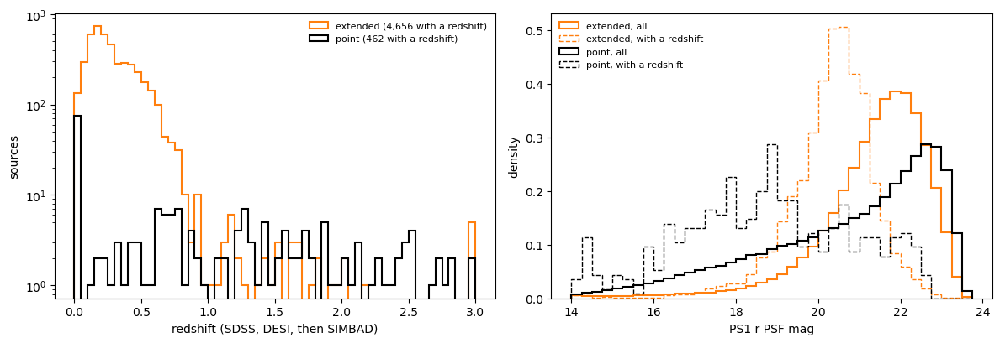

In [ ]:
# redshifts of the extended sources that have one, and magnitudes of the spectroscopic subsets
z = pd.concat([xm.sdss_z.where(xm.sdss_matched), xm.desi_z.where(xm.desi_matched), xm.simbad_z.where(xm.simbad_matched)], axis=1).bfill(axis=1).iloc[:, 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for k, c in (('extended', 'C1'), ('point', 'k')):
    s = (xm['sample'] == k) & np.isfinite(z)
    axes[0].hist(z[s].clip(upper=3), bins=np.linspace(0, 3, 61), histtype='step', color=c, lw=1.5, label=f'{k} ({s.sum():,} with a redshift)')
axes[0].set_xlabel('redshift (SDSS, DESI, then SIMBAD)'); axes[0].set_ylabel('sources'); axes[0].set_yscale('log'); axes[0].legend(frameon=False, fontsize=8)
m = xm_in[f'{b}_ps1_psf']
for k, c in (('extended', 'C1'), ('point', 'k')):
    s = xm['sample'] == k
    axes[1].hist(m[s], bins=np.arange(14, 24, 0.25), histtype='step', color=c, lw=1.5, density=True, label=f'{k}, all')
    axes[1].hist(m[s & np.isfinite(z)], bins=np.arange(14, 24, 0.25), histtype='step', color=c, lw=1, ls='--', density=True, label=f'{k}, with a redshift')
axes[1].set_xlabel('PS1 r PSF mag'); axes[1].set_ylabel('density'); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

18,235 PS1 stars with r < 14 in the field


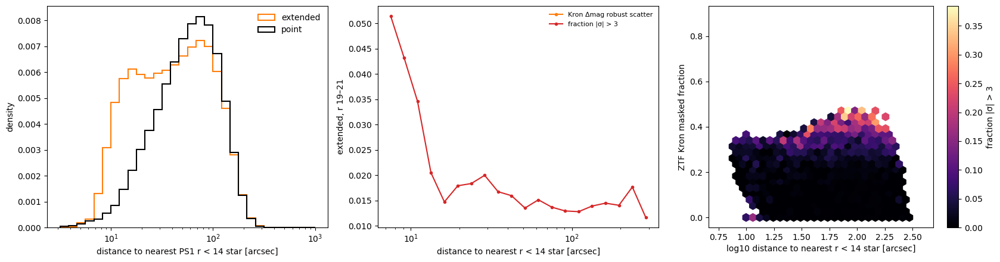

extended r 19–21 within 30" of a r < 14 star: 11.5% of them, holding 18% of their |σ| > 3
extended r 19–21 within 60" of a r < 14 star: 30.4% of them, holding 37% of their |σ| > 3
extended r 19–21 within 120" of a r < 14 star: 72.2% of them, holding 74% of their |σ| > 3


In [ ]:
# location: distance to the nearest bright star (PS1 r PSF < 14 in the field) and the masked fraction of the ZTF Kron aperture
bright = ps1[ps1.rPSFMag < 14]
d_bright, _ = cKDTree(xyz(bright.ra.values, bright.dec.values)).query(xyz(xm_in.ra.values, xm_in.dec.values))
xm['bright_dist'] = np.degrees(2 * np.arcsin(d_bright / 2)) * 3600
print(f'{len(bright):,} PS1 stars with r < 14 in the field')
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
db = np.logspace(0.5, 3, 31)
for k, c in (('extended', 'C1'), ('point', 'k')):
    s = xm['sample'] == k
    axes[0].hist(xm.bright_dist[s], bins=db, histtype='step', color=c, lw=1.5, density=True, label=k)
axes[0].set_xscale('log'); axes[0].set_xlabel('distance to nearest PS1 r < 14 star [arcsec]'); axes[0].set_ylabel('density'); axes[0].legend(frameon=False)
mag = (xm_in[f'{b}_ztf_use'] + xm_in[f'{b}_ps1_use']) / 2
e = (xm['sample'] == 'extended') & (mag > 19) & (mag < 21)
cen, scat, frac_out = [], [], []
for lo, hi in zip(db[:-1], db[1:]):
    s = e & (xm.bright_dist >= lo) & (xm.bright_dist < hi)
    if s.sum() < 50: continue
    d = xm_in.dmag_kron[s]
    cen.append(np.sqrt(lo * hi)); scat.append(mad(d)); frac_out.append(np.mean(np.abs(xm_in[f'{b}_sigma'][s]) > 3))
axes[1].plot(cen, scat, 'C1.-', label='Kron Δmag robust scatter'); axes[1].plot(cen, frac_out, 'C3.-', label='fraction |σ| > 3')
axes[1].set_xscale('log'); axes[1].set_xlabel('distance to nearest r < 14 star [arcsec]'); axes[1].set_title(None); axes[1].legend(frameon=False, fontsize=8)
axes[1].set_ylabel('extended, r 19–21')
h = axes[2].hexbin(np.log10(xm.bright_dist[e]), xm_in.kron_masked[e], C=np.abs(xm_in[f'{b}_sigma'][e]) > 3, gridsize=30, reduce_C_function=np.mean, cmap='magma', mincnt=20)
plt.colorbar(h, ax=axes[2], label='fraction |σ| > 3'); axes[2].set_xlabel('log10 distance to nearest r < 14 star [arcsec]'); axes[2].set_ylabel('ZTF Kron masked fraction')
plt.tight_layout(); plt.show()
for r_cut in (30, 60, 120):
    near = e & (xm.bright_dist < r_cut)
    print(f'extended r 19–21 within {r_cut}" of a r < 14 star: {near.sum() / e.sum() * 100:.1f}% of them, holding {np.sum(near & (np.abs(xm_in[f"{b}_sigma"]) > 3)) / np.sum(e & (np.abs(xm_in[f"{b}_sigma"]) > 3)) * 100:.0f}% of their |σ| > 3')

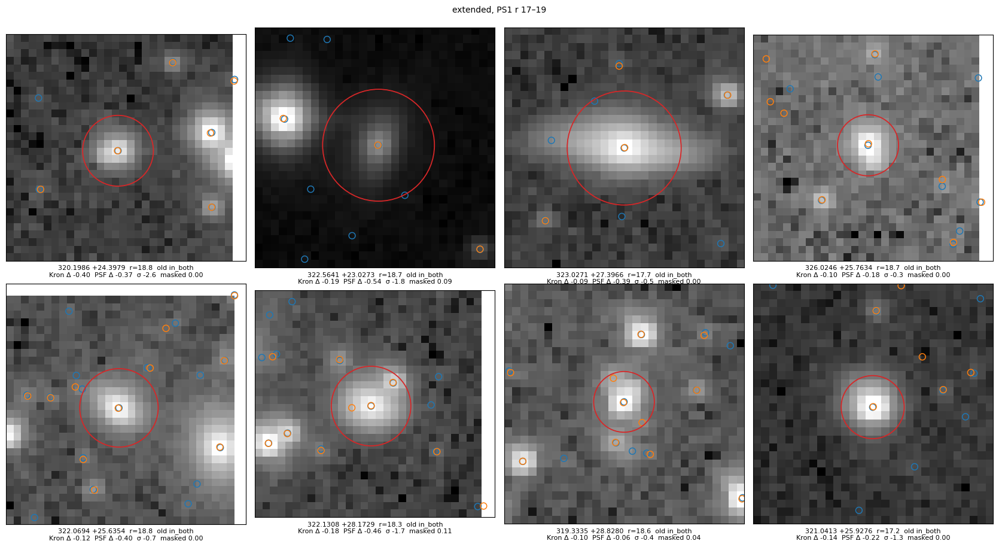

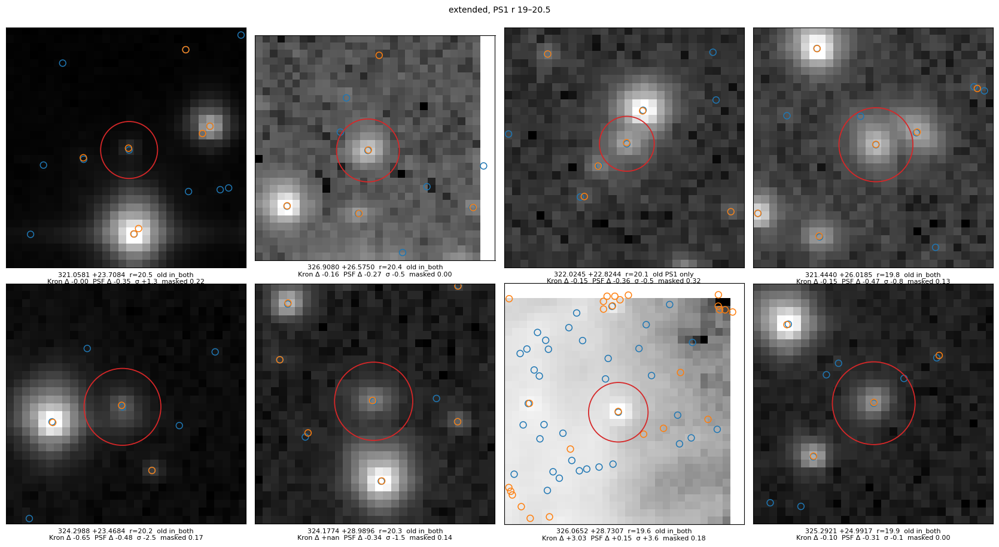

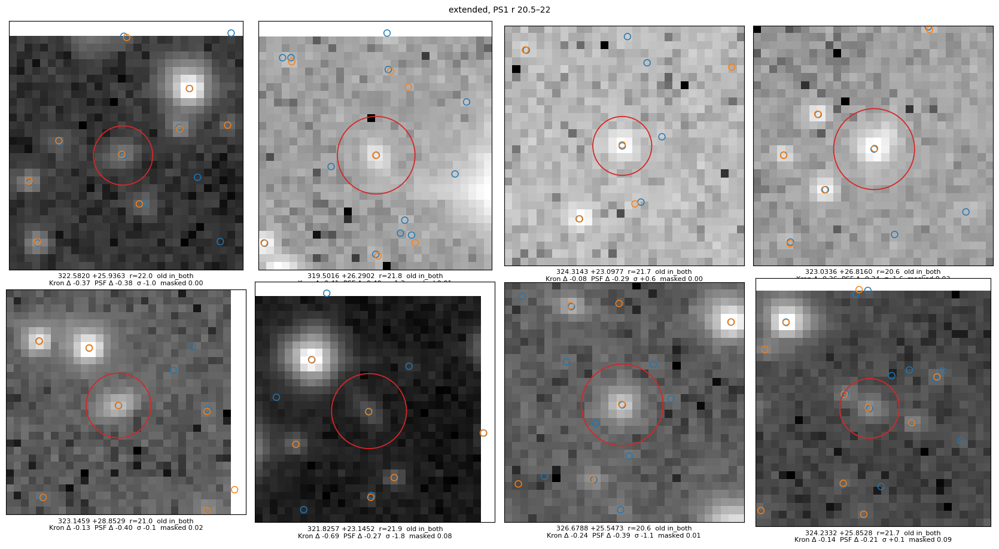

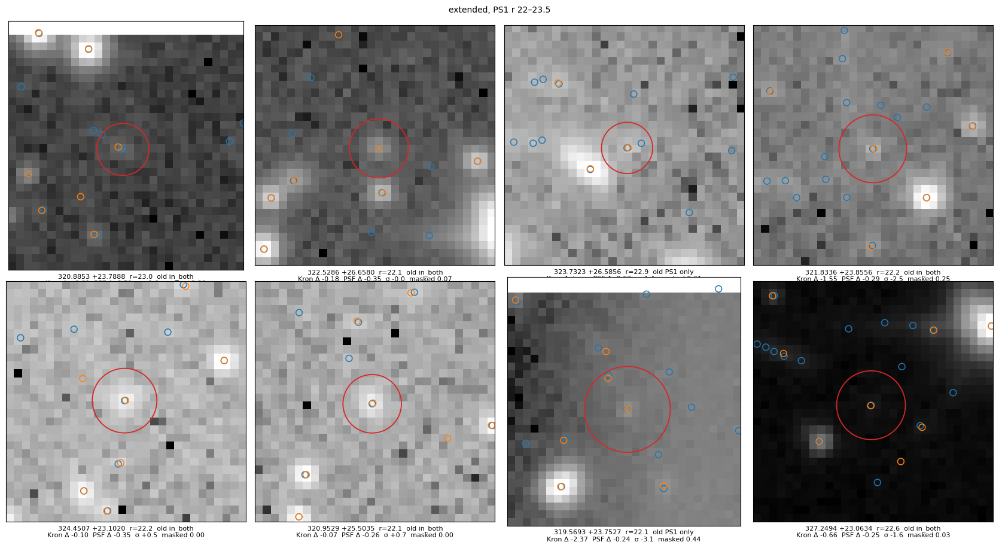

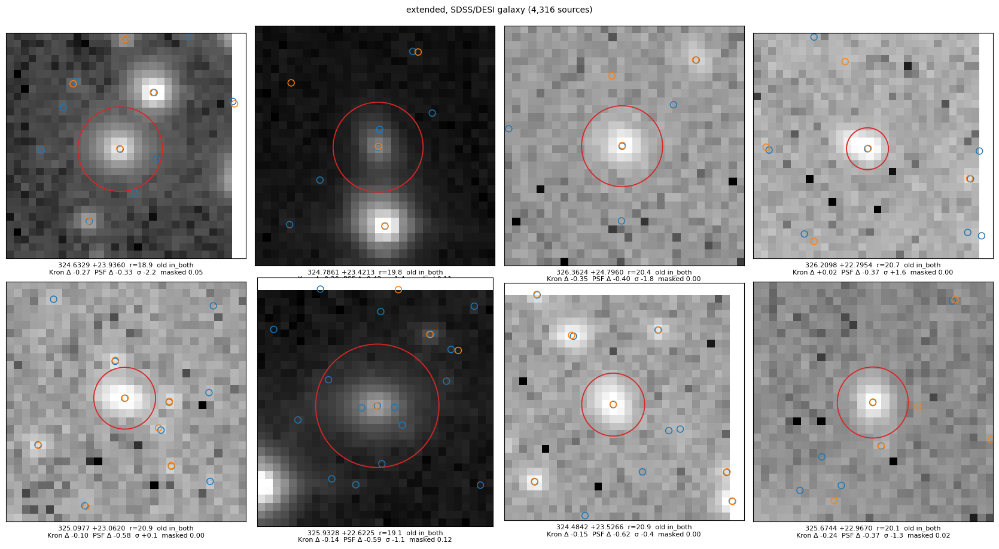

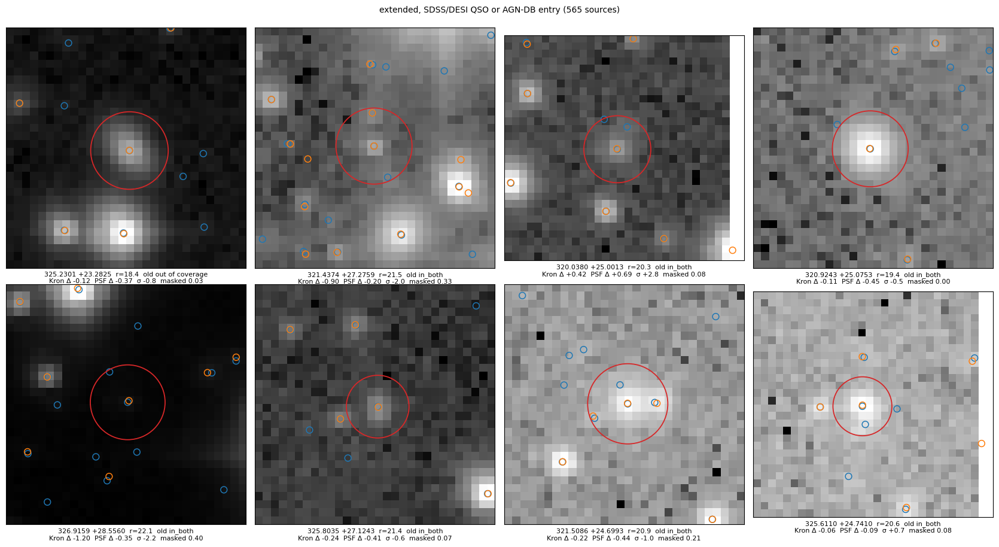

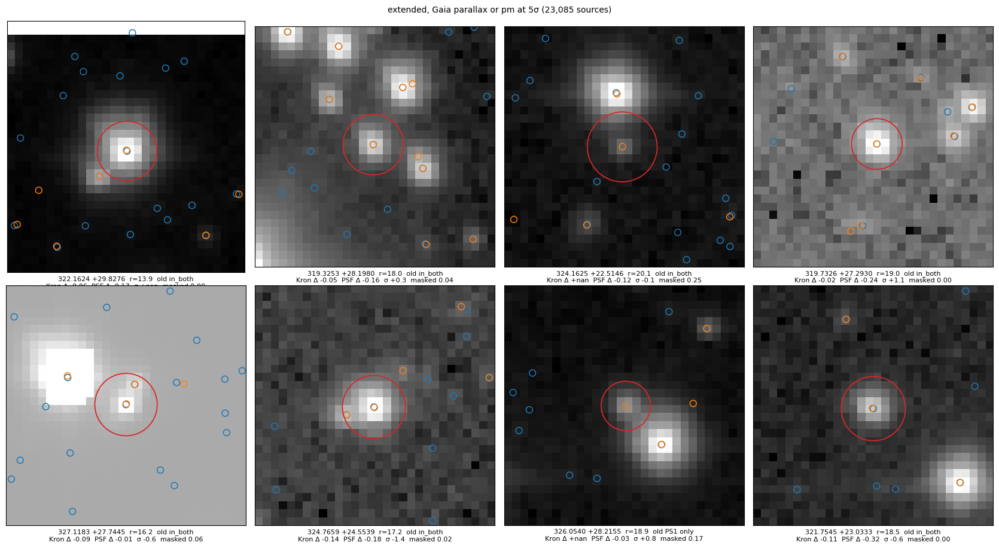

In [ ]:
# cutouts: random extended sources per magnitude bin, and per catalog class
emag = xm_in[f'{b}_ps1_psf']
for lo, hi in ((17, 19), (19, 20.5), (20.5, 22), (22, 23.5)):
    s = (xm['sample'] == 'extended') & (emag >= lo) & (emag < hi)
    ext_cutouts(xm_in[s].sample(8, random_state=1), f'extended, PS1 r {lo}–{hi}')
for lab, sel in (('SDSS/DESI galaxy', ((xm.sdss_class.astype(str) == 'GALAXY') | (xm.desi_spectype.astype(str) == 'GALAXY'))),
                 ('SDSS/DESI QSO or AGN-DB entry', ((xm.sdss_class.astype(str) == 'QSO') | (xm.desi_spectype.astype(str) == 'QSO') | xm.agn_db_matched.fillna(False))),
                 ('Gaia parallax or pm at 5σ', xm.gaia_star)):
    s = (xm['sample'] == 'extended') & sel.fillna(False).astype(bool)
    if s.sum(): ext_cutouts(xm_in[s].sample(min(8, s.sum()), random_state=1), f'extended, {lab} ({s.sum():,} sources)')

### 3d. Contaminated Kron apertures: drop them, or fall back to PSF

An extended `in_both` source's Kron magnitude is "contaminated" when more than 10% of its ZTF Kron aperture is masked (other sources' watershed basins or bad pixels; `ff.KRON_MAX_MASKED`). Two treatments, each run through the whole filter with vote morphology (`filter_dev(base, 'vote', kron_policy)`):

1. **drop**: as now, extended sources are judged on Kron magnitudes against an envelope built on the mixed PSF/Kron sample, but bands with a contaminated Kron aperture are removed (no envelope contribution, no σ).
2. **psf**: extended sources use Kron only when the aperture is clean; contaminated ones are judged on PSF magnitudes like point sources.

Top rows: the envelopes and the points that build them; then the ±3σ edges side by side, the counts, and the branch statistics.

In [ ]:
KEEP = lambda b: [f'{b}_cat', f'{b}_point', f'{b}_use_kron', f'{b}_kron_contaminated', f'{b}_dmag', f'{b}_sigma', f'{b}_ztf_use', f'{b}_ps1_use']
# the object table and Gaia match (`base`, section 2) do not depend on the policy: rerun only catalogs/envelopes/branches
runs = {}
for pol in ('drop', 'psf'):
    s_, env_, c_, w_ = filter_dev(base, 'vote', pol, verbose=True)
    runs[pol] = dict(src=s_[[c for b in 'gri' for c in KEEP(b)]].copy(), env=env_, cands=c_, wfs=w_)
    del s_
for pol, r in runs.items():
    print(pol + ': ' + '; '.join(f"{b}: in_both {(r['src'][f'{b}_cat'] == 0).sum():,}, Kron {r['src'][f'{b}_use_kron'].sum():,}, contaminated {r['src'][f'{b}_kron_contaminated'].sum():,}" for b in 'gri'))

/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "pmsafe" yielded 1466991 of "distance overridden (Note 6)", 133 of "binary logical OR of the above warnings"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


Filtering in_both
Filtering in_ztf
Filtering in_pstarr
Filtering in_both
Filtering in_ztf
Filtering in_pstarr
drop: g: in_both 1,357,727, Kron 99,904, contaminated 94,073; r: in_both 1,982,402, Kron 156,117, contaminated 186,327; i: in_both 2,335,053, Kron 180,730, contaminated 201,137
psf: g: in_both 1,400,297, Kron 99,904, contaminated 94,073; r: in_both 2,080,326, Kron 156,117, contaminated 186,327; i: in_both 2,458,568, Kron 180,730, contaminated 201,137


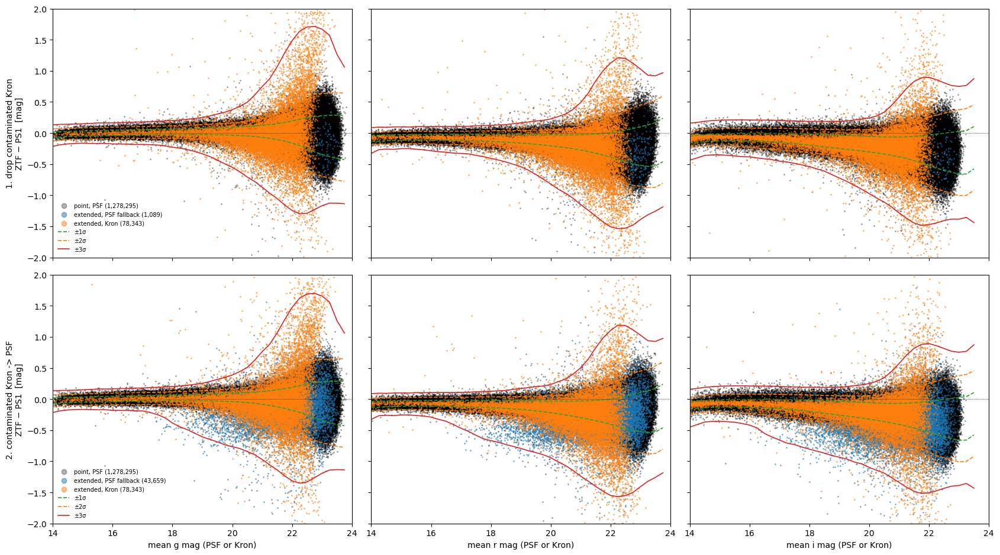

In [ ]:
LEVELS = [(-3, 'C3'), (-2, 'C1'), (-1, 'C2'), (1, 'C2'), (2, 'C1'), (3, 'C3')]
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5), sharex=True, sharey=True)
rng = np.random.default_rng(0)
for row, (pol, title) in enumerate((('drop', '1. drop contaminated Kron'), ('psf', '2. contaminated Kron -> PSF'))):
    r = runs[pol]
    for ax, b in zip(axes[row], 'gri'):
        s = r['src'][r['src'][f'{b}_cat'] == 0]
        mag = (s[f'{b}_ztf_use'] + s[f'{b}_ps1_use']).values / 2; d = s[f'{b}_dmag'].values
        kron = s[f'{b}_use_kron'].values; fb = (~s[f'{b}_point'].values) & ~kron
        show = rng.random(len(s)) < min(1, 300_000 / max(len(s), 1))
        ax.scatter(mag[show & ~kron & ~fb], d[show & ~kron & ~fb], s=1, alpha=0.3, color='k', rasterized=True, label=f'point, PSF ({(~kron & ~fb).sum():,})')
        if fb.any(): ax.scatter(mag[show & fb], d[show & fb], s=1, alpha=0.5, color='C0', rasterized=True, label=f'extended, PSF fallback ({fb.sum():,})')
        ax.scatter(mag[show & kron], d[show & kron], s=1, alpha=0.5, color='C1', rasterized=True, label=f'extended, Kron ({kron.sum():,})')
        e = r['env'][b]
        for n, c in LEVELS:
            ax.plot(e.mag_grid, e.get_percentile(e.mag_grid, norm.cdf(n)), color=c, lw=1.2, ls='-' if abs(n) == 3 else '--', label=f'±{n}σ' if n > 0 else None)
        ax.axhline(0, color='k', lw=0.6, ls=':'); ax.set_xlim(14, 24); ax.set_ylim(-2, 2)
        if row == 1: ax.set_xlabel(f'mean {b} mag (PSF or Kron)')
        if b == 'g': ax.set_ylabel(f'{title}\nZTF − PS1  [mag]'); ax.legend(frameon=False, fontsize=7, markerscale=6, loc='lower left')
plt.tight_layout(); plt.show()

In [ ]:
# the ±3σ edges side by side, and how many sources each method judges and selects
grid = np.array([15, 16, 17, 18, 19, 20, 21, 22, 23])
rows = []
for b in 'gri':
    for pol in ('drop', 'psf'):
        e = runs[pol]['env'][b]; hi, lo = e.get_percentile(grid, norm.cdf(3)), e.get_percentile(grid, norm.cdf(-3))
        rows.append({'band': b, 'method': pol, **{f'{m:.0f}': f'{h:+.2f}/{l:+.2f}' for m, h, l in zip(grid, hi, lo)}})
print('±3σ edges [mag] at mean magnitude'); display(pd.DataFrame(rows).set_index(['band', 'method']))
counts = pd.DataFrame({pol: {**{f'{b}: in_both judged': f"{(r['src'][f'{b}_cat'] == 0).sum():,}" for b in 'gri'},
                             **{f'{b}: extended on Kron': f"{r['src'][f'{b}_use_kron'].sum():,}" for b in 'gri'},
                             **{f'{b}: |σ| > 3 in in_both': f"{((r['src'][f'{b}_cat'] == 0) & (np.abs(r['src'][f'{b}_sigma']) > 3)).sum():,}" for b in 'gri'},
                             **{f'candidates, {n}': f'{len(c):,}' for n, c in r['cands'].items()}} for pol, r in runs.items()})
display(counts)
for n in ff.CATALOG.values():
    a, b_ = runs['drop']['wfs'][n].stats.set_index('step'), runs['psf']['wfs'][n].stats.set_index('step')
    print(f'--- {n}: drop | psf'); display(pd.concat({'drop': a, 'psf': b_}, axis=1))

±3σ edges [mag] at mean magnitude


15           16           17           18           19  \
band method                                                                    
g    drop    +0.15/-0.16  +0.16/-0.18  +0.18/-0.18  +0.20/-0.23  +0.25/-0.33   
     psf     +0.15/-0.17  +0.16/-0.18  +0.18/-0.19  +0.20/-0.39  +0.25/-0.61   
r    drop    +0.10/-0.25  +0.10/-0.29  +0.11/-0.33  +0.12/-0.41  +0.16/-0.54   
     psf     +0.10/-0.26  +0.10/-0.29  +0.11/-0.47  +0.12/-0.67  +0.17/-0.79   
i    drop    +0.21/-0.35  +0.21/-0.38  +0.20/-0.45  +0.19/-0.54  +0.19/-0.72   
     psf     +0.21/-0.36  +0.21/-0.42  +0.20/-0.66  +0.19/-0.81  +0.19/-0.94   

                      20           21           22           23  
band method                                                      
g    drop    +0.37/-0.55  +0.75/-0.87  +1.48/-1.24  +1.67/-1.17  
     psf     +0.39/-0.76  +0.76/-0.97  +1.47/-1.31  +1.66/-1.19  
r    drop    +0.23/-0.82  +0.49/-1.15  +1.12/-1.51  +1.03/-1.39  
     psf     +0.23/-0.94  +0.50/-1.24  +1.10/-1.55  +1.03/-1.41  
i    drop    +0.24/-0.97  +0.58/-1.28  +0.90/-1.47  +0.75/-1.38  
     psf     +0.25/-1.10  +0.57/-1.34  +0.89/-1.51  +0.75/-1.39

,drop,psf
g: in_both judged,"1,357,727","1,400,297"
r: in_both judged,"1,982,402","2,080,326"
i: in_both judged,"2,335,053","2,458,568"
g: extended on Kron,"99,904","99,904"
r: extended on Kron,"156,117","156,117"
i: extended on Kron,"180,730","180,730"
g: |σ| > 3 in in_both,"3,021","3,094"
r: |σ| > 3 in in_both,"4,448","4,640"
i: |σ| > 3 in in_both,"5,430","5,636"
"candidates, in_both",470,726


--- in_both: drop | psf


drop                        psf           \
                                        g        r        i        g        r   
step                                                                            
objects detected in both          1555769  2281265  2899059  1555769  2281265   
ZTF flags == 0; PS1 quality       1470302  2116600  2503185  1470302  2116600   
PSF SNR >= 5 on both sides        1357727  1982402  2335053  1400297  2080326   
|sigma| > 3                          3021     4448     5430     3094     4640   
|sigma| > 3 in >= 2 bands             393      662      542      554      870   
no Gaia proper motion at 5 sigma      239      431      370      418      667   
no Gaia parallax at 5 sigma           239      431      370      417      666   

                                           
                                        i  
step                                       
objects detected in both          2899059  
ZTF flags == 0; PS1 quality       2503185  
PSF SNR >= 5 on both sides        2458568  
|sigma| > 3                          5636  
|sigma| > 3 in >= 2 bands             706  
no Gaia proper motion at 5 sigma      555  
no Gaia parallax at 5 sigma           555

--- in_ztf: drop | psf


drop                    \
                                                          g        r        i   
step                                                                            
objects in in_ztf (other side undetected or SNR...  1512039  1702603  1391682   
ZTF flags == 0                                      1488172  1668097  1366888   
PSF SNR >= 5                                         340446   628637   464547   
|sigma| > 3                                           43802    50050    76200   
|sigma| > 3 in >= 2 bands                             10181    12991    11399   
no unmatched counterpart within 3"                     7233     9063     8005   
no Gaia proper motion at 5 sigma                       6735     8420     7519   
no Gaia parallax at 5 sigma                            6732     8416     7518   

                                                        psf                    
                                                          g        r        i  
step                                                                           
objects in in_ztf (other side undetected or SNR...  1512039  1702603  1391682  
ZTF flags == 0                                      1488172  1668097  1366888  
PSF SNR >= 5                                         391949   717040   542169  
|sigma| > 3                                           50461    60484    99345  
|sigma| > 3 in >= 2 bands                             14347    18829    16888  
no unmatched counterpart within 3"                    10712    13768    12445  
no Gaia proper motion at 5 sigma                      10131    13039    11886  
no Gaia parallax at 5 sigma                           10128    13035    11885

--- in_pstarr: drop | psf


drop                  \
                                                         g       r       i   
step                                                                         
objects in in_pstarr (other side undetected or ...  347026  245025  387546   
PS1 quality                                         170580  107578  173860   
PSF SNR >= 5                                        169419  106908  173676   
|sigma| > 3                                          14651   31357   63615   
|sigma| > 3 in >= 2 bands                             4611   10873   10596   
no unmatched counterpart within 3"                    1571    3162    3015   
no Gaia proper motion at 5 sigma                       756    1499    1435   
no Gaia parallax at 5 sigma                            754    1496    1432   

                                                       psf                  
                                                         g       r       i  
step                                                                        
objects in in_pstarr (other side undetected or ...  347026  245025  387546  
PS1 quality                                         170580  107578  173860  
PSF SNR >= 5                                        169419  106908  173676  
|sigma| > 3                                          14899   31154   63398  
|sigma| > 3 in >= 2 bands                             4641   10857   10569  
no unmatched counterpart within 3"                    1585    3165    3011  
no Gaia proper motion at 5 sigma                       769    1502    1432  
no Gaia parallax at 5 sigma                            767    1499    1429

## 4. Candidates

Per branch: position, the bands that qualified, per-band Δmag and σ (negative = brighter in ZTF), morphology and the Gaia match; then r-band cutouts of the first few (ZTF reference image, 40", north up east left).

In [ ]:
cols = lambda b: [f'{b}_cat', f'{b}_dmag', f'{b}_sigma', f'{b}_point']
for name, c in cands.items():
    print(f'=== {name}: {len(c)} candidates')
    if len(c) == 0: continue
    show = c[['ra', 'dec', 'n_big_dmag_bands', 'gaia_sep_arcsec'] + sum((cols(b) for b in 'gri'), [])].copy()
    show = show.sort_values('n_big_dmag_bands', ascending=False)
    with pd.option_context('display.width', 250, 'display.max_columns', 30, 'display.float_format', '{:.3f}'.format):
        display(show.head(15))

=== in_both: 823 candidates


,ra,dec,n_big_dmag_bands,gaia_sep_arcsec,g_cat,g_dmag,g_sigma,g_point,r_cat,r_dmag,r_sigma,r_point,i_cat,i_dmag,i_sigma,i_point
2927976,319.434,27.824,3,0.037,0,-0.647,-3.016,False,0,-1.096,-3.407,False,0,-0.762,-3.146,False
3331806,325.661,28.949,3,0.212,0,0.965,3.063,False,0,2.482,3.455,False,0,1.843,3.137,False
511047,323.121,23.389,3,NaN,0,-2.623,-3.331,False,0,2.650,3.488,False,0,3.233,3.518,False
3369306,327.479,28.768,3,NaN,0,-2.646,-3.323,False,0,-2.474,-3.208,False,0,-2.696,-3.481,False
3445308,324.674,29.836,3,NaN,0,-1.294,-3.103,False,0,-1.366,-3.115,False,0,-2.006,-3.240,False
1165030,326.958,25.044,3,0.013,0,1.131,3.129,True,0,0.846,3.108,True,0,0.937,3.053,True
3461327,324.608,29.827,3,NaN,0,2.710,3.507,False,0,2.991,3.553,False,0,3.273,3.774,False
2403803,323.452,27.600,3,NaN,0,-3.311,-3.756,False,0,-2.645,-3.272,False,0,-2.874,-3.603,False
2403683,323.449,27.609,3,0.084,0,-3.114,-3.603,False,0,-2.306,-3.189,False,0,-2.607,-3.580,False
3463303,324.673,29.840,3,NaN,0,-1.940,-3.202,False,0,-1.520,-3.107,False,0,-1.949,-3.207,False


=== in_ztf: 13952 candidates


,ra,dec,n_big_dmag_bands,gaia_sep_arcsec,g_cat,g_dmag,g_sigma,g_point,r_cat,r_dmag,r_sigma,r_point,i_cat,i_dmag,i_sigma,i_point
1275494,324.696,25.496,3,NaN,1,-3.640,-3.953,True,1,-4.018,-3.921,True,1,-4.201,-4.408,True
4185519,320.144,28.839,3,NaN,1,-3.671,-3.963,True,1,-3.702,-3.746,True,1,-5.231,-8.000,False
1415254,323.851,24.458,3,NaN,1,-4.904,-4.583,False,1,-4.325,-4.112,False,1,-3.894,-4.204,False
4171088,319.788,28.830,3,NaN,1,-2.658,-3.399,False,1,-2.662,-3.329,False,1,-2.490,-3.301,False
4170953,320.144,28.846,3,NaN,1,-4.003,-4.030,False,1,-3.498,-3.663,False,1,-3.486,-3.909,False
1417222,324.247,24.499,3,NaN,1,-2.530,-3.335,True,1,-2.894,-3.465,True,1,-2.981,-3.604,True
1417302,323.876,24.473,3,NaN,1,-2.401,-3.270,False,1,-3.005,-3.516,False,1,-2.109,-3.061,False
1417322,323.867,24.467,3,NaN,1,-4.602,-4.223,False,1,-3.975,-3.895,False,1,-4.018,-4.296,False
1417387,323.869,24.442,3,NaN,1,-3.491,-3.876,True,1,-3.367,-3.622,True,1,-3.221,-3.736,True
4130528,319.267,29.273,3,NaN,1,-2.054,-3.080,False,1,-3.203,-3.582,False,1,-2.721,-3.449,True


=== in_pstarr: 1633 candidates


,ra,dec,n_big_dmag_bands,gaia_sep_arcsec,g_cat,g_dmag,g_sigma,g_point,r_cat,r_dmag,r_sigma,r_point,i_cat,i_dmag,i_sigma,i_point
6685976,325.797,23.996,3,3.407,2,2.068,3.222,True,2,1.922,3.426,True,2,1.146,3.062,True
6827405,320.057,25.346,3,0.064,2,3.366,4.321,True,2,3.749,4.591,True,2,3.215,4.330,True
6858742,320.526,25.661,3,0.078,2,2.433,3.544,True,2,3.430,4.451,True,2,3.127,4.286,True
6852772,324.832,25.609,3,NaN,2,1.873,3.078,True,2,2.513,3.852,True,2,2.557,3.967,True
6850827,320.966,25.603,3,0.034,2,1.866,3.074,True,2,3.225,4.297,True,2,3.374,4.401,True
6842804,325.928,25.530,3,0.038,2,2.552,3.674,True,2,2.678,4.058,True,2,2.516,3.982,True
6840231,321.905,25.504,3,0.043,2,3.008,4.030,True,2,3.230,4.393,True,2,2.920,4.203,True
6840132,320.570,25.507,3,0.158,2,2.797,3.865,True,2,3.298,4.351,True,2,2.875,4.185,True
6838343,324.441,25.480,3,0.066,2,2.666,3.751,True,2,2.973,4.183,True,2,2.780,4.108,True
6834023,319.744,25.432,3,3.681,2,8.755,8.000,False,2,9.348,8.000,False,2,8.932,8.000,False


in_both


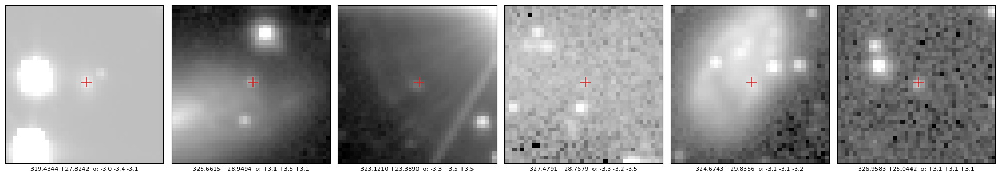

in_ztf


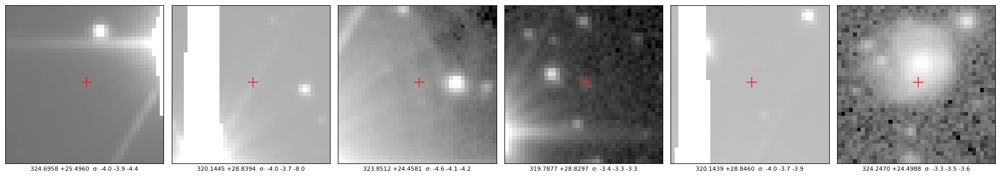

in_pstarr


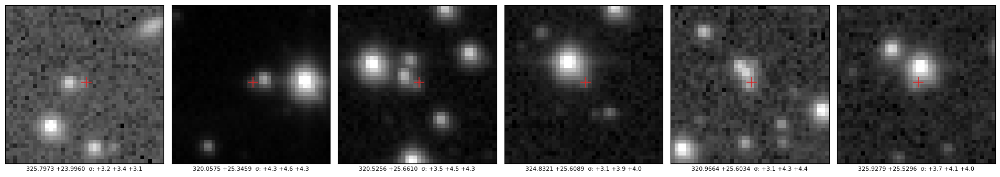

In [ ]:
def cutouts(rows, n=6, size=40):
    rows = rows.head(n)
    fig, axes = plt.subplots(1, len(rows), figsize=(3.2 * len(rows), 3.4), squeeze=False)
    for ax, (_, r) in zip(axes[0], rows.iterrows()):
        im = ztf_image(int(r.ccd), int(r.qid), 'r')
        cut = Cutout2D(im.data, SkyCoord(r.ra * u.deg, r.dec * u.deg), size * u.arcsec, wcs=im.wcs)
        data = cut.data[::-1, ::-1] if im.wcs.pixel_scale_matrix[0, 0] > 0 else cut.data
        ax.imshow(data, origin='lower', cmap='gray', norm=simple_norm(np.nan_to_num(data), 'log', percent=99.5))
        ax.plot(data.shape[1] / 2, data.shape[0] / 2, '+', color='C3', ms=14, mew=1.2)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(f"{r.ra:.4f} {r.dec:+.4f}  σ: " + ' '.join(f'{r[f"{b}_sigma"]:+.1f}' if np.isfinite(r[f'{b}_sigma']) else '-' for b in 'gri'), fontsize=8)
    plt.tight_layout(); plt.show()

for name, c in cands.items():
    if len(c):
        print(name); cutouts(c.sort_values('n_big_dmag_bands', ascending=False))

## 5. The final pipeline

`ff.filter_field` with no options. Everything is decided per object:

- **catalog**: one per object -- `in_both` (a ZTF object with a PS1 object within 1"), `in_ztf` (no PS1 object) or `in_pstarr` (a PS1 object with no ZTF object, where ZTF covers it);
- **bands**: each band makes one comparison within that catalog -- both measured, ZTF against the PS1 limit, or PS1 against the ZTF limit. A band PS1 did not measure on a PS1 object is unusable, not a non-detection; in `in_both` a side below S/N 5 becomes the limit side; a ZTF non-detection needs ZTF coverage;
- **cuts**: every per-band cut removes the band for all later steps, and an object leaves as soon as fewer than two usable bands remain;
- **morphology**: one per object. Per band, PSF − Kron − 0.05 in units of its error, combined over ZTF and PS1 by inverse variance; extended when that exceeds 3σ in ≥ 2 of the measured bands. PSF magnitudes for point sources, Kron for extended ones; a band whose extended source has a ZTF Kron aperture more than 10% masked is dropped;
- one KDE envelope per band from the usable both-measured bands; candidates have |σ| > 3 in ≥ 2 usable bands, ≥ 2 of them of the same sign.

Every cut is its own step below; the counts are objects, split by the exact combination of bands still in.

In [4]:
for v in ('src', 'envelopes', 'cands', 'wfs', 'base', 'runs', 'morph_runs'):   # free the development runs; filter_field prepares the field itself
    globals().pop(v, None)
src_f, env_f, cands_f, wfs_f = ff.filter_field(FIELD, data_dir=D)
print('candidates:', {n: len(c) for n, c in cands_f.items()})

/Users/adamboesky/opt/anaconda3/envs/long_transients/lib/python3.12/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "pmsafe" yielded 1466991 of "distance overridden (Note 6)", 133 of "binary logical OR of the above warnings"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


Filtering in_both
Filtering in_ztf
Filtering in_pstarr
candidates: {'in_both': 802, 'in_ztf': 13795, 'in_pstarr': 2055}


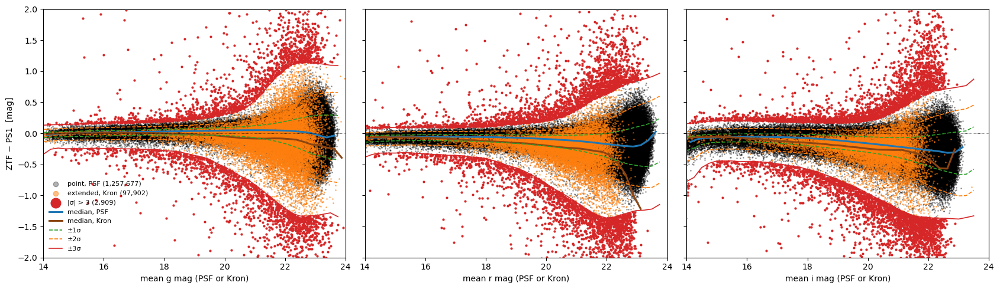

In [9]:
# the final envelopes and the in_both sample that builds them
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
rng = np.random.default_rng(0)
LEVELS = [(-3, 'C3'), (-2, 'C1'), (-1, 'C2'), (1, 'C2'), (2, 'C1'), (3, 'C3')]
for ax, b in zip(axes, 'gri'):
    s = src_f[src_f[f'{b}_cat'] == 0]
    mag = (s[f'{b}_ztf_use'].values + s[f'{b}_ps1_use'].values) / 2; d = s[f'{b}_dmag'].values
    kr, big = s[f'{b}_use_kron'].values, np.abs(s[f'{b}_sigma'].values) > ff.SIGMA_BOUNDARY
    show = rng.random(len(s)) < min(1, 300_000 / max(len(s), 1))
    ax.scatter(mag[show & ~kr], d[show & ~kr], s=1, alpha=0.3, color='k', rasterized=True, label=f'point, PSF ({(~kr).sum():,})')
    ax.scatter(mag[show & kr], d[show & kr], s=1, alpha=0.5, color='C1', rasterized=True, label=f'extended, Kron ({kr.sum():,})')
    ax.scatter(mag[big], d[big], s=4, color='C3', rasterized=True, label=f'|σ| > {ff.SIGMA_BOUNDARY:.0f} ({big.sum():,})')
    edges = np.arange(14, 24.01, 0.25); mid = (edges[1:] + edges[:-1]) / 2
    for sel, col, lab in ((~kr, 'tab:blue', 'median, PSF'), (kr, 'saddlebrown', 'median, Kron')):
        idx = np.digitize(mag[sel], edges) - 1
        med = np.array([np.median(d[sel][idx == i]) if np.sum(idx == i) >= 20 else np.nan for i in range(len(mid))])
        ax.plot(mid, med, color=col, lw=2.2, label=lab)
    e = env_f[b]
    for n, c in LEVELS:
        ax.plot(e.mag_grid, e.get_percentile(e.mag_grid, norm.cdf(n)), color=c, lw=1.2, ls='-' if abs(n) == 3 else '--', label=f'±{n}σ' if n > 0 else None)
    ax.axhline(0, color='k', lw=0.6, ls=':'); ax.set_xlim(14, 24); ax.set_ylim(-2, 2); ax.set_xlabel(f'mean {b} mag (PSF or Kron)')
    if b == 'g': ax.set_ylabel('ZTF − PS1  [mag]'); ax.legend(frameon=False, fontsize=8, markerscale=6, loc='lower left')
plt.tight_layout(); plt.show()

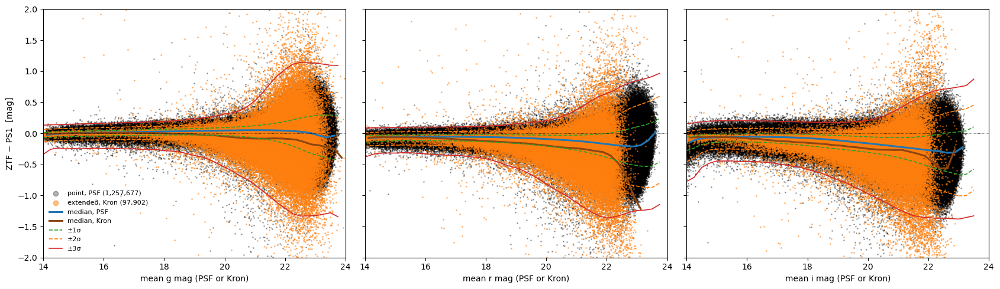

In [11]:
# the final envelopes and the in_both sample that builds them
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
rng = np.random.default_rng(0)
LEVELS = [(-3, 'C3'), (-2, 'C1'), (-1, 'C2'), (1, 'C2'), (2, 'C1'), (3, 'C3')]
for ax, b in zip(axes, 'gri'):
    s = src_f[src_f[f'{b}_cat'] == 0]
    mag = (s[f'{b}_ztf_use'].values + s[f'{b}_ps1_use'].values) / 2; d = s[f'{b}_dmag'].values
    kr, big = s[f'{b}_use_kron'].values, np.abs(s[f'{b}_sigma'].values) > ff.SIGMA_BOUNDARY
    show = rng.random(len(s)) < min(1, 300_000 / max(len(s), 1))
    ax.scatter(mag[~kr], d[~kr], s=1, alpha=0.3, color='k', rasterized=True, label=f'point, PSF ({(~kr).sum():,})')
    ax.scatter(mag[kr], d[kr], s=1, alpha=0.5, color='C1', rasterized=True, label=f'extended, Kron ({kr.sum():,})')
    # ax.scatter(mag[big], d[big], s=4, color='C3', rasterized=True, label=f'|σ| > {ff.SIGMA_BOUNDARY:.0f} ({big.sum():,})')
    edges = np.arange(14, 24.01, 0.25); mid = (edges[1:] + edges[:-1]) / 2
    for sel, col, lab in ((~kr, 'tab:blue', 'median, PSF'), (kr, 'saddlebrown', 'median, Kron')):
        idx = np.digitize(mag[sel], edges) - 1
        med = np.array([np.median(d[sel][idx == i]) if np.sum(idx == i) >= 20 else np.nan for i in range(len(mid))])
        ax.plot(mid, med, color=col, lw=2.2, label=lab)
    e = env_f[b]
    for n, c in LEVELS:
        ax.plot(e.mag_grid, e.get_percentile(e.mag_grid, norm.cdf(n)), color=c, lw=1.2, ls='-' if abs(n) == 3 else '--', label=f'±{n}σ' if n > 0 else None)
    ax.axhline(0, color='k', lw=0.6, ls=':'); ax.set_xlim(14, 24); ax.set_ylim(-2, 2); ax.set_xlabel(f'mean {b} mag (PSF or Kron)')
    if b == 'g': ax.set_ylabel('ZTF − PS1  [mag]'); ax.legend(frameon=False, fontsize=8, markerscale=6, loc='lower left')
plt.tight_layout(); plt.show()

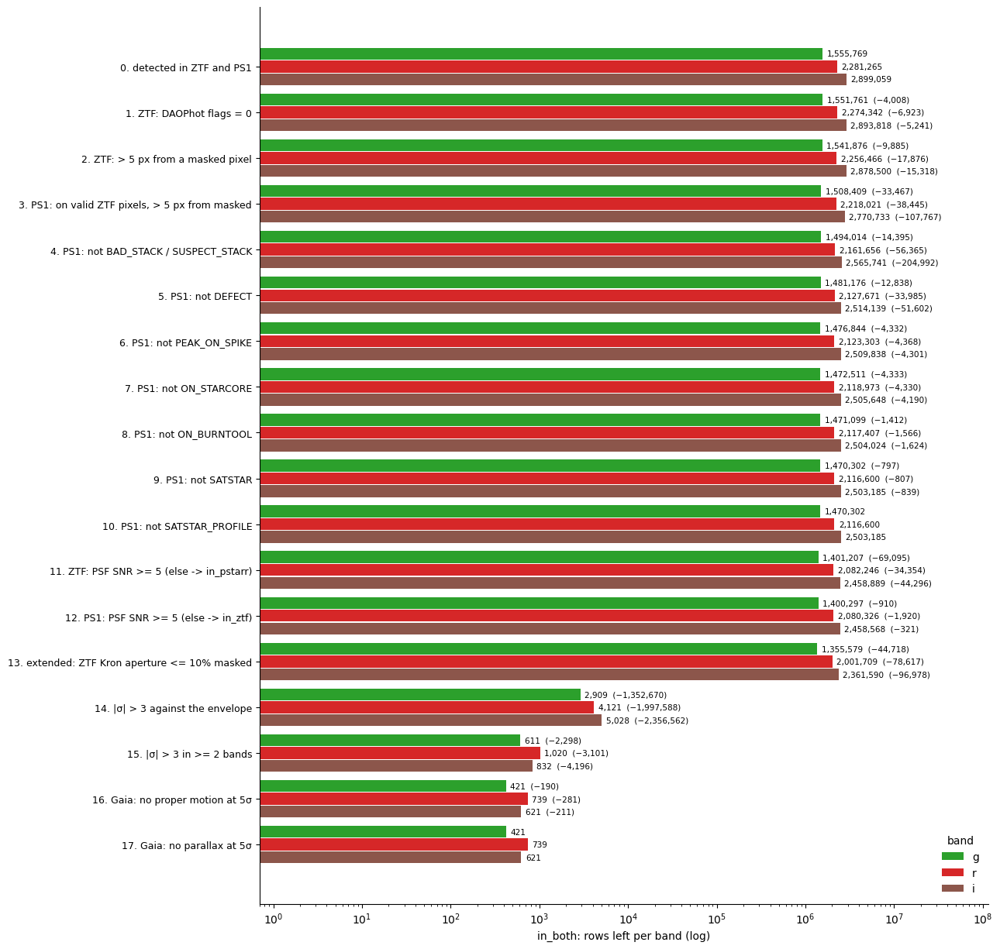

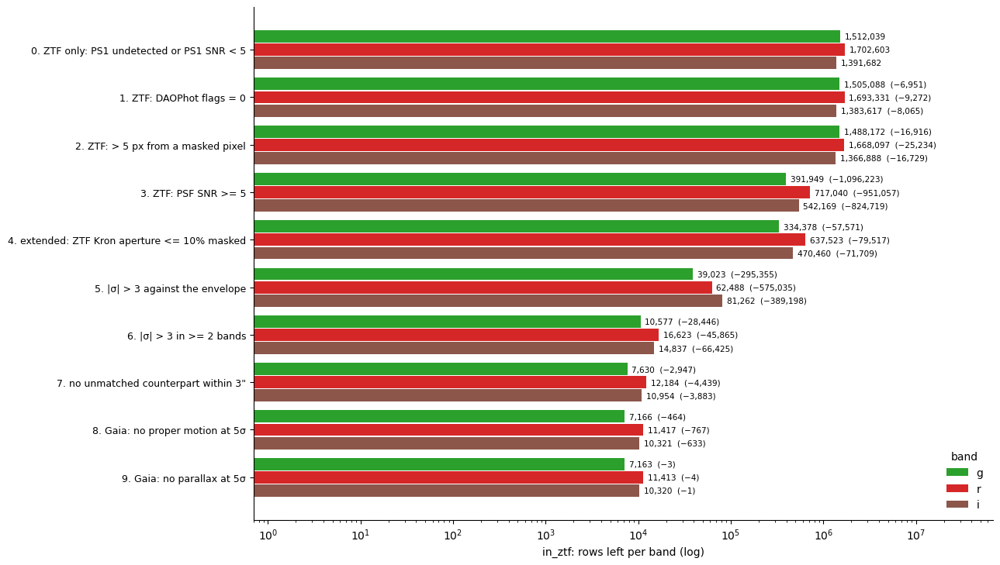

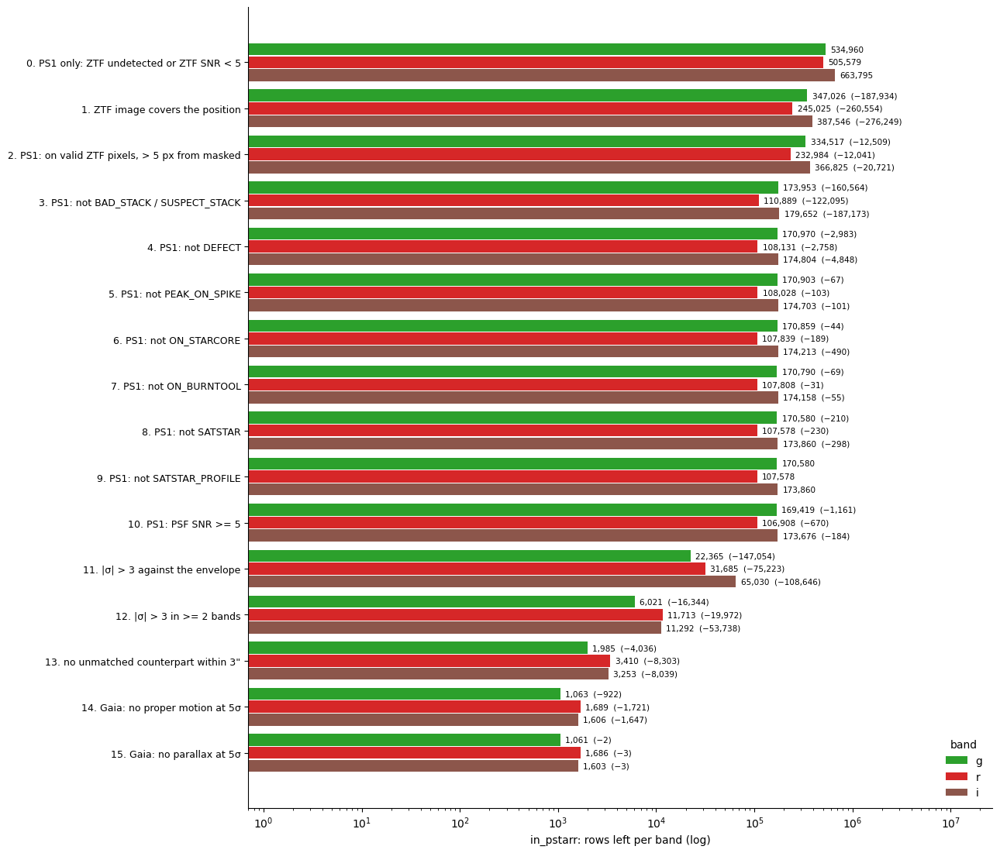

In [6]:
# one chart per branch: objects left after each cut (each object needs >= 2 usable bands throughout), with the split by
# the exact combination of bands still in, as in the old flowcharts
COMBO_COLOR = {'gri': '0.25', 'gr': 'tab:green', 'gi': 'tab:purple', 'ri': 'tab:red'}
for name, wf in wfs_f.items():
    st = wf.stats.set_index('step')
    n = len(st); y = np.arange(n)
    fig, ax = plt.subplots(figsize=(15, 0.62 * n + 1.2))
    v = st['objects'].to_numpy(float); prev = np.r_[np.nan, v[:-1]]
    ax.barh(y, np.maximum(v, 0.7), height=0.7, color='0.55')
    for i in range(n):
        combos = ', '.join(f'{c}: {st[c].iloc[i]:,}' for c in ff.COMBOS)
        ax.text(max(v[i], 0.7) * 1.12, y[i], f'{v[i]:,.0f}' + (f'  (−{prev[i] - v[i]:,.0f})' if prev[i] > v[i] else '') + f'   [{combos}]', va='center', fontsize=8)
    ax.set_yticks(y, [f'{i}. {s}' for i, s in enumerate(st.index)], fontsize=9); ax.invert_yaxis()
    ax.set_xscale('log'); ax.set_xlim(0.7, np.nanmax(v) * 3e4)
    ax.set_xlabel(f'{name}: objects left (log)')
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); plt.show()

--- in_both


left                    \
                                                    g        r        i   
step                                                                      
detected in ZTF and PS1                       1555769  2281265  2899059   
ZTF: DAOPhot flags = 0                        1551761  2274342  2893818   
ZTF: > 5 px from a masked pixel               1541876  2256466  2878500   
PS1: on valid ZTF pixels, > 5 px from masked  1508409  2218021  2770733   
PS1: not BAD_STACK / SUSPECT_STACK            1494014  2161656  2565741   
PS1: not DEFECT                               1481176  2127671  2514139   
PS1: not PEAK_ON_SPIKE                        1476844  2123303  2509838   
PS1: not ON_STARCORE                          1472511  2118973  2505648   
PS1: not ON_BURNTOOL                          1471099  2117407  2504024   
PS1: not SATSTAR                              1470302  2116600  2503185   
PS1: not SATSTAR_PROFILE                      1470302  2116600  2503185   
ZTF: PSF SNR >= 5 (else -> in_pstarr)         1401207  2082246  2458889   
PS1: PSF SNR >= 5 (else -> in_ztf)            1400297  2080326  2458568   
extended: ZTF Kron aperture <= 10% masked     1355579  2001709  2361590   
|σ| > 3 against the envelope                     2909     4121     5028   
|σ| > 3 in >= 2 bands                             611     1020      832   
Gaia: no proper motion at 5σ                      421      739      621   
Gaia: no parallax at 5σ                           421      739      621   

                                              removed                    
                                                    g        r        i  
step                                                                     
detected in ZTF and PS1                             0        0        0  
ZTF: DAOPhot flags = 0                           4008     6923     5241  
ZTF: > 5 px from a masked pixel                  9885    17876    15318  
PS1: on valid ZTF pixels, > 5 px from masked    33467    38445   107767  
PS1: not BAD_STACK / SUSPECT_STACK              14395    56365   204992  
PS1: not DEFECT                                 12838    33985    51602  
PS1: not PEAK_ON_SPIKE                           4332     4368     4301  
PS1: not ON_STARCORE                             4333     4330     4190  
PS1: not ON_BURNTOOL                             1412     1566     1624  
PS1: not SATSTAR                                  797      807      839  
PS1: not SATSTAR_PROFILE                            0        0        0  
ZTF: PSF SNR >= 5 (else -> in_pstarr)           69095    34354    44296  
PS1: PSF SNR >= 5 (else -> in_ztf)                910     1920      321  
extended: ZTF Kron aperture <= 10% masked       44718    78617    96978  
|σ| > 3 against the envelope                  1352670  1997588  2356562  
|σ| > 3 in >= 2 bands                            2298     3101     4196  
Gaia: no proper motion at 5σ                      190      281      211  
Gaia: no parallax at 5σ                             0        0        0

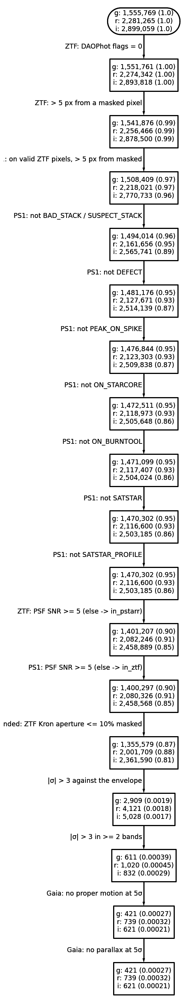

--- in_ztf


left                    removed  \
                                                 g        r        i        g   
step                                                                            
ZTF only: PS1 undetected or PS1 SNR < 5    1512039  1702603  1391682        0   
ZTF: DAOPhot flags = 0                     1505088  1693331  1383617     6951   
ZTF: > 5 px from a masked pixel            1488172  1668097  1366888    16916   
ZTF: PSF SNR >= 5                           391949   717040   542169  1096223   
extended: ZTF Kron aperture <= 10% masked   334378   637523   470460    57571   
|σ| > 3 against the envelope                 39023    62488    81262   295355   
|σ| > 3 in >= 2 bands                        10577    16623    14837    28446   
no unmatched counterpart within 3"            7630    12184    10954     2947   
Gaia: no proper motion at 5σ                  7166    11417    10321      464   
Gaia: no parallax at 5σ                       7163    11413    10320        3   

                                                           
                                                r       i  
step                                                       
ZTF only: PS1 undetected or PS1 SNR < 5         0       0  
ZTF: DAOPhot flags = 0                       9272    8065  
ZTF: > 5 px from a masked pixel             25234   16729  
ZTF: PSF SNR >= 5                          951057  824719  
extended: ZTF Kron aperture <= 10% masked   79517   71709  
|σ| > 3 against the envelope               575035  389198  
|σ| > 3 in >= 2 bands                       45865   66425  
no unmatched counterpart within 3"           4439    3883  
Gaia: no proper motion at 5σ                  767     633  
Gaia: no parallax at 5σ                         4       1

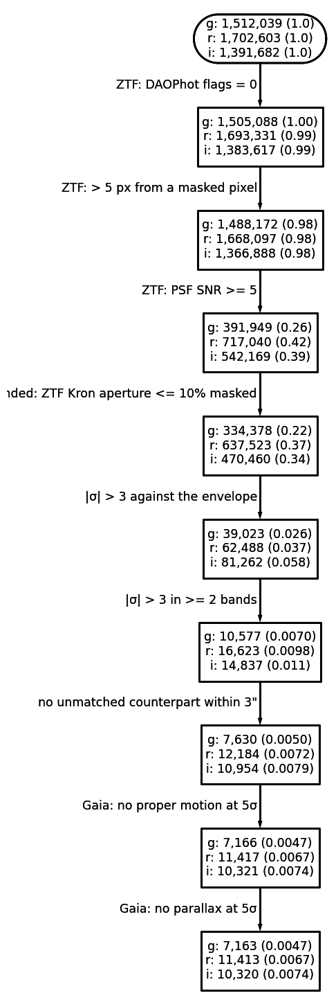

--- in_pstarr


left                 removed  \
                                                   g       r       i       g   
step                                                                           
PS1 only: ZTF undetected or ZTF SNR < 5       534960  505579  663795       0   
ZTF image covers the position                 347026  245025  387546  187934   
PS1: on valid ZTF pixels, > 5 px from masked  334517  232984  366825   12509   
PS1: not BAD_STACK / SUSPECT_STACK            173953  110889  179652  160564   
PS1: not DEFECT                               170970  108131  174804    2983   
PS1: not PEAK_ON_SPIKE                        170903  108028  174703      67   
PS1: not ON_STARCORE                          170859  107839  174213      44   
PS1: not ON_BURNTOOL                          170790  107808  174158      69   
PS1: not SATSTAR                              170580  107578  173860     210   
PS1: not SATSTAR_PROFILE                      170580  107578  173860       0   
PS1: PSF SNR >= 5                             169419  106908  173676    1161   
|σ| > 3 against the envelope                   22365   31685   65030  147054   
|σ| > 3 in >= 2 bands                           6021   11713   11292   16344   
no unmatched counterpart within 3"              1985    3410    3253    4036   
Gaia: no proper motion at 5σ                    1063    1689    1606     922   
Gaia: no parallax at 5σ                         1061    1686    1603       2   

                                                              
                                                   r       i  
step                                                          
PS1 only: ZTF undetected or ZTF SNR < 5            0       0  
ZTF image covers the position                 260554  276249  
PS1: on valid ZTF pixels, > 5 px from masked   12041   20721  
PS1: not BAD_STACK / SUSPECT_STACK            122095  187173  
PS1: not DEFECT                                 2758    4848  
PS1: not PEAK_ON_SPIKE                           103     101  
PS1: not ON_STARCORE                             189     490  
PS1: not ON_BURNTOOL                              31      55  
PS1: not SATSTAR                                 230     298  
PS1: not SATSTAR_PROFILE                           0       0  
PS1: PSF SNR >= 5                                670     184  
|σ| > 3 against the envelope                   75223  108646  
|σ| > 3 in >= 2 bands                          19972   53738  
no unmatched counterpart within 3"              8303    8039  
Gaia: no proper motion at 5σ                    1721    1647  
Gaia: no parallax at 5σ                            3       3

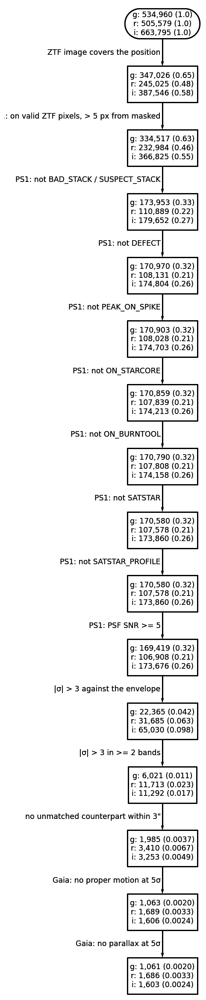

In [7]:
# the same as tables (objects and their band combinations after each step), and the old-style flowcharts
for name, wf in wfs_f.items():
    print(f'--- {name}'); display(wf.stats.set_index('step'))
    display(wf.flowchart(f'{name} ({FIELD})'))

In [8]:
cols = lambda b: [f'{b}_cat', f'{b}_dmag', f'{b}_sigma', f'{b}_point']
for name, c in cands_f.items():
    print(f'=== {name}: {len(c)} candidates')
    if len(c) == 0: continue
    show = c[['ra', 'dec', 'n_big_dmag_bands', 'gaia_sep_arcsec'] + sum((cols(b) for b in 'gri'), [])].sort_values('n_big_dmag_bands', ascending=False)
    with pd.option_context('display.width', 250, 'display.max_columns', 30, 'display.float_format', '{:.3f}'.format):
        display(show.head(15))

=== in_both: 802 candidates


,ra,dec,n_big_dmag_bands,gaia_sep_arcsec,g_cat,g_dmag,g_sigma,g_point,r_cat,r_dmag,r_sigma,r_point,i_cat,i_dmag,i_sigma,i_point
529,326.675,24.076,3,0.053,0,0.571,3.392,True,0,0.512,3.536,True,0,0.206,3.037,True
3048996,319.652,26.474,3,NaN,0,-1.400,-3.380,False,0,-1.372,-3.396,False,0,-1.168,-3.126,False
1101150,326.301,25.138,3,0.031,0,0.555,3.205,True,0,0.610,3.500,True,0,0.275,3.040,True
1112241,325.529,24.755,3,0.057,0,0.412,3.052,True,0,0.293,3.138,True,0,0.400,3.335,True
3012913,319.363,26.855,3,NaN,0,1.188,3.085,False,0,1.189,3.544,False,0,1.012,3.357,False
1122152,326.103,24.390,3,0.040,0,0.759,3.393,True,0,0.464,3.381,True,0,0.474,3.549,True
1131323,325.601,24.660,3,0.053,0,-1.545,-3.812,False,0,-0.753,-3.410,False,0,-0.623,-3.051,False
2978722,319.514,27.674,3,NaN,0,0.905,3.066,True,0,0.516,3.141,True,0,0.657,3.347,True
2978270,319.900,27.723,3,0.116,0,-1.134,-3.568,True,0,-0.912,-3.330,True,0,-0.772,-3.022,True
1151571,326.203,24.337,3,NaN,0,1.214,3.506,True,0,1.069,3.567,True,0,0.878,3.520,True


=== in_ztf: 13795 candidates


,ra,dec,n_big_dmag_bands,gaia_sep_arcsec,g_cat,g_dmag,g_sigma,g_point,r_cat,r_dmag,r_sigma,r_point,i_cat,i_dmag,i_sigma,i_point
3590575,324.252,28.346,3,NaN,1,-1.849,-3.511,True,1,-2.428,-3.856,True,1,-2.564,-4.006,True
2117241,327.312,27.158,3,NaN,1,-1.673,-3.341,True,1,-1.954,-3.513,True,1,-2.117,-3.648,True
779882,320.850,23.908,3,NaN,1,-1.374,-3.045,True,1,-1.939,-3.502,True,1,-2.265,-3.770,True
779737,320.733,23.995,3,NaN,1,-1.451,-3.123,True,1,-2.001,-3.547,True,1,-2.269,-3.774,True
779516,320.377,23.271,3,NaN,1,-1.401,-3.073,True,1,-1.952,-3.512,True,1,-2.260,-3.766,True
779445,320.833,23.292,3,NaN,1,-2.289,-3.923,True,1,-2.921,-4.201,True,1,-3.112,-4.427,True
778672,320.650,23.456,3,NaN,1,-2.299,-3.933,True,1,-3.097,-4.266,True,1,-3.309,-4.603,True
3601133,324.287,28.826,3,NaN,1,-1.498,-3.169,True,1,-3.238,-4.282,True,1,-4.501,-5.298,True
3601081,323.821,28.203,3,NaN,1,-3.356,-4.486,True,1,-3.420,-4.285,True,1,-3.520,-4.781,True
775619,320.354,23.298,3,NaN,1,-2.621,-4.227,True,1,-2.186,-3.682,True,1,-2.623,-4.048,True


=== in_pstarr: 2055 candidates


,ra,dec,n_big_dmag_bands,gaia_sep_arcsec,g_cat,g_dmag,g_sigma,g_point,r_cat,r_dmag,r_sigma,r_point,i_cat,i_dmag,i_sigma,i_point
7295101,323.905,29.841,3,0.041,2,3.077,4.394,True,2,3.817,5.610,True,2,3.607,4.584,True
6985181,319.852,26.936,3,0.043,2,2.505,4.150,True,2,2.857,4.443,True,2,2.419,4.219,True
6989053,326.273,26.976,3,0.020,2,2.191,3.901,True,2,3.120,4.594,True,2,2.913,4.425,True
6989820,327.296,26.988,3,0.041,2,2.054,3.799,True,2,3.220,4.646,True,2,2.946,4.434,True
6999111,323.939,27.079,3,0.029,2,2.573,4.187,True,2,3.107,4.617,True,2,2.975,4.441,True
7006532,326.940,27.109,3,0.057,2,2.490,4.112,True,2,2.721,4.350,True,2,2.253,4.133,True
7010108,326.985,27.154,3,NaN,2,1.876,3.663,True,2,2.315,4.147,True,2,1.635,3.730,True
7011311,324.294,27.167,3,NaN,2,2.469,4.111,True,2,2.830,4.433,True,2,2.588,4.305,True
7016304,326.549,27.211,3,NaN,2,1.922,3.699,False,2,3.088,4.556,False,2,2.861,4.414,False
7023991,325.934,27.302,3,0.029,2,1.949,3.718,True,2,2.699,4.356,True,2,2.671,4.338,True
